In [2]:

# Import required libraries

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


In [3]:
DATASET_PATH = "/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset"

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

dataset = datasets.ImageFolder(
    root=DATASET_PATH,
    transform=transform
)

print("Total images:", len(dataset))
print("Classes:", dataset.classes)
print("Class mapping:", dataset.class_to_idx)

Total images: 681
Classes: ['normal', 'potholes']
Class mapping: {'normal': 0, 'potholes': 1}


In [4]:
from torch.utils.data import DataLoader, random_split

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset, [train_size, val_size]
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=64, shuffle=False
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 544
Validation images: 137


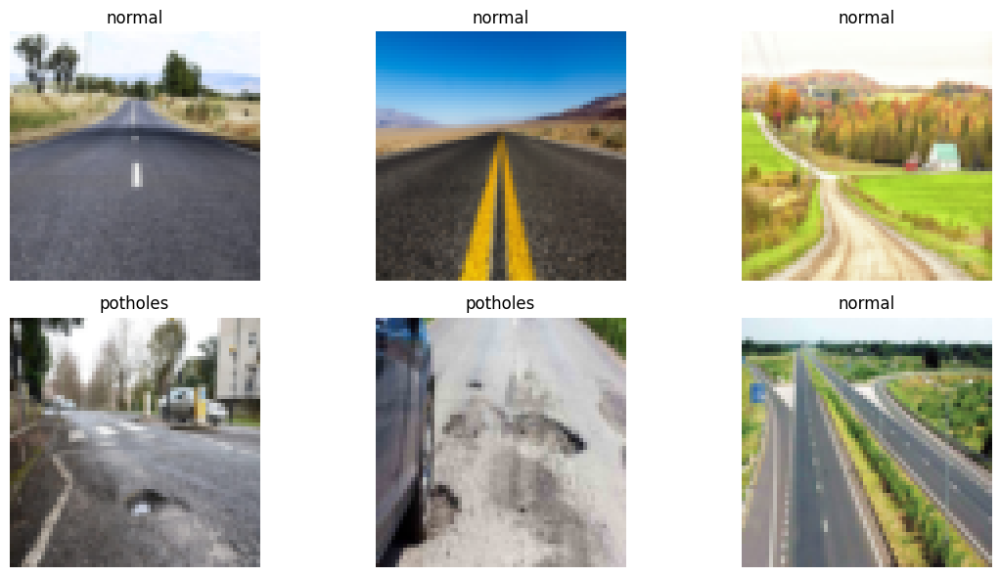

In [5]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 6))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i].permute(1, 2, 0))
    plt.title(dataset.classes[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 2)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x


model = CNN().to(device)

print(model)

CNN(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=

In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [8]:
num_epochs = 10

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):

    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(f"Epoch [{epoch+1}/{num_epochs}] "
          f"Train Loss: {train_loss:.4f}, "
          f"Train Accuracy: {train_accuracy:.2f}%, "
          f"Val Loss: {val_loss:.4f}, "
          f"Val Accuracy: {val_accuracy:.2f}%")

Epoch [1/10] Train Loss: 1.8167, Train Accuracy: 61.76%, Val Loss: 0.9203, Val Accuracy: 55.47%
Epoch [2/10] Train Loss: 0.6214, Train Accuracy: 80.15%, Val Loss: 0.6541, Val Accuracy: 66.42%
Epoch [3/10] Train Loss: 0.3483, Train Accuracy: 86.40%, Val Loss: 0.9001, Val Accuracy: 62.77%
Epoch [4/10] Train Loss: 0.2561, Train Accuracy: 89.52%, Val Loss: 0.3554, Val Accuracy: 83.21%
Epoch [5/10] Train Loss: 0.2287, Train Accuracy: 89.34%, Val Loss: 0.2806, Val Accuracy: 87.59%
Epoch [6/10] Train Loss: 0.2225, Train Accuracy: 91.18%, Val Loss: 0.2013, Val Accuracy: 91.97%
Epoch [7/10] Train Loss: 0.1905, Train Accuracy: 92.46%, Val Loss: 0.1656, Val Accuracy: 90.51%
Epoch [8/10] Train Loss: 0.1721, Train Accuracy: 92.10%, Val Loss: 0.2402, Val Accuracy: 87.59%
Epoch [9/10] Train Loss: 0.1641, Train Accuracy: 92.46%, Val Loss: 0.1548, Val Accuracy: 91.97%
Epoch [10/10] Train Loss: 0.1493, Train Accuracy: 94.67%, Val Loss: 0.1356, Val Accuracy: 92.70%


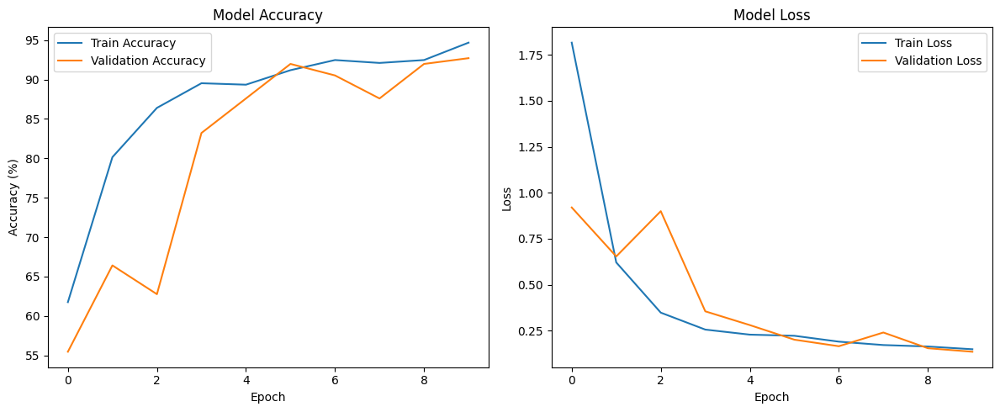

In [9]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [10]:
y_true = []
y_pred = []

model.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        y_true.extend(labels.numpy())
        y_pred.extend(predicted.cpu().numpy())

print("Predictions collected successfully!")

Predictions collected successfully!


In [11]:
print(classification_report(
    y_true,
    y_pred,
    target_names=['Normal', 'Potholes']
))

              precision    recall  f1-score   support

      Normal       0.98      0.85      0.91        61
    Potholes       0.89      0.99      0.94        76

    accuracy                           0.93       137
   macro avg       0.94      0.92      0.92       137
weighted avg       0.93      0.93      0.93       137



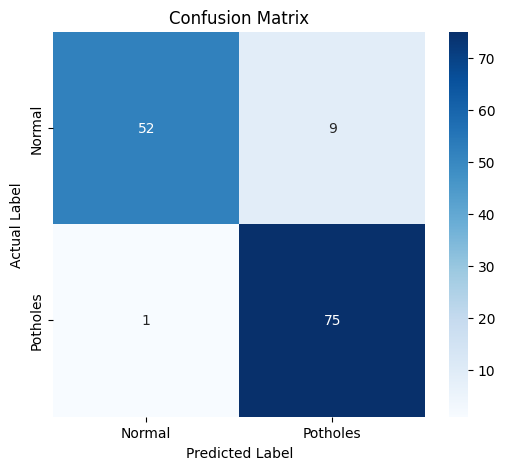

In [12]:
cm = confusion_matrix(y_true, y_pred)
class_names = ['normal', 'potholes']
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Potholes'],
    yticklabels=['Normal', 'Potholes']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')
plt.show()

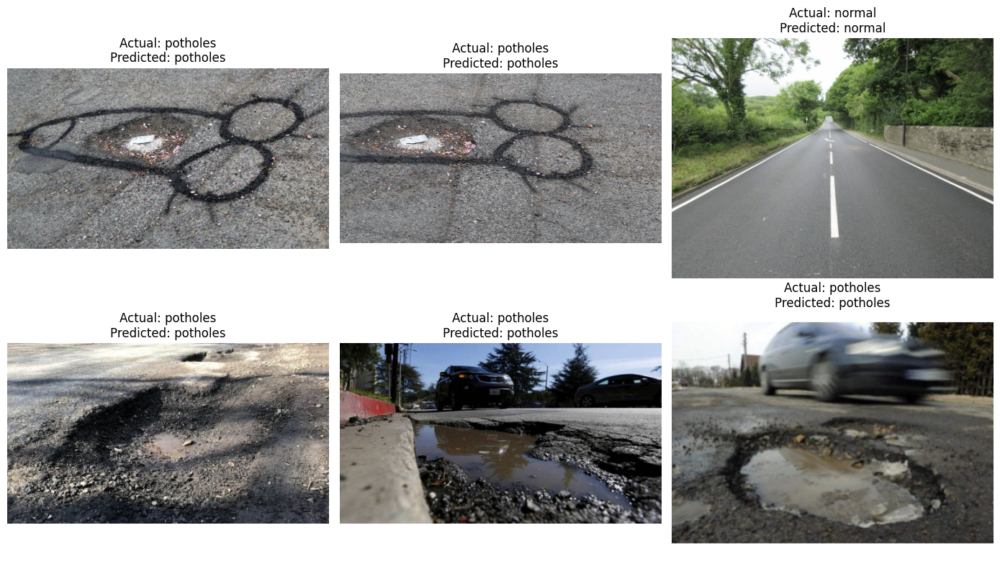

In [13]:
from PIL import Image

plt.figure(figsize=(14, 8))

for i in range(6):
    plt.subplot(2, 3, i + 1)

    # Get original image path
    image_path, actual_label = dataset.samples[val_dataset.indices[i]]

    # Load original image without resizing
    img = Image.open(image_path).convert("RGB")

    plt.imshow(img)

    actual = class_names[actual_label]
    predicted = class_names[y_pred[i]]

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [60]:
# ORIGINAL-RESOLUTION VISUALIZATION FOR ANY CLASSIFICATION MODEL
# Predictions use resized tensors, but displayed images are loaded from original file paths.

import random
import math
from PIL import Image
import matplotlib.pyplot as plt
import torch


def visualize_original_predictions(
    model,
    validation_loader,
    original_dataset,
    validation_indices,
    class_names,
    model_name="Model",
    max_correct=3,
    max_misclassified=3,
    random_seed=42
):
    """Show a small random sample of correct and incorrect validation predictions.

    IMPORTANT: validation_loader must have shuffle=False and must follow the same
    order as validation_indices. original_dataset should be the original ImageFolder.
    """
    model.eval()
    actual_labels = []
    predicted_labels = []

    with torch.no_grad():
        for images, labels in validation_loader:
            images = images.to(device)
            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            actual_labels.extend(labels.cpu().numpy().tolist())
            predicted_labels.extend(predictions.cpu().numpy().tolist())

    if len(actual_labels) != len(validation_indices):
        raise ValueError(
            f"Prediction count ({len(actual_labels)}) does not match "
            f"validation index count ({len(validation_indices)}). "
            "Check that the validation loader uses the same subset and shuffle=False."
        )

    correct = []
    misclassified = []

    for dataset_index, actual, predicted in zip(
        validation_indices, actual_labels, predicted_labels
    ):
        item = (dataset_index, int(actual), int(predicted))
        if actual == predicted:
            correct.append(item)
        else:
            misclassified.append(item)

    rng = random.Random(random_seed)
    correct_to_show = rng.sample(correct, min(max_correct, len(correct)))
    wrong_to_show = rng.sample(misclassified, min(max_misclassified, len(misclassified)))

    print(f"{model_name}: {len(correct)} correctly classified, "
          f"{len(misclassified)} misclassified out of {len(validation_indices)} validation images.")

    def display_group(items, heading, filename, is_correct):
        if not items:
            print(f"No {heading.lower()} images to display for {model_name}.")
            return

        cols = min(3, len(items))
        rows = math.ceil(len(items) / cols)
        fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 5 * rows), squeeze=False)
        axes = axes.flatten()

        for ax, (dataset_index, actual, predicted) in zip(axes, items):
            image_path, _ = original_dataset.samples[dataset_index]
            with Image.open(image_path) as source_image:
                img = source_image.convert("RGB").copy()

            ax.imshow(img)
            ax.set_title(
                f"Actual: {class_names[actual]}\nPredicted: {class_names[predicted]}",
                fontsize=12,
                color="green" if is_correct else "red"
            )
            ax.axis("off")

        for ax in axes[len(items):]:
            ax.axis("off")

        fig.suptitle(f"{model_name} - {heading}", fontsize=16)
        plt.tight_layout()
        plt.show()

    display_group(correct_to_show, "Correctly Classified", "correct", True)
    display_group(wrong_to_show, "Misclassified", "misclassified", False)

    return {
        "correct_count": len(correct),
        "misclassified_count": len(misclassified),
        "total": len(validation_indices),
        "correct_examples": correct_to_show,
        "misclassified_examples": wrong_to_show
    }


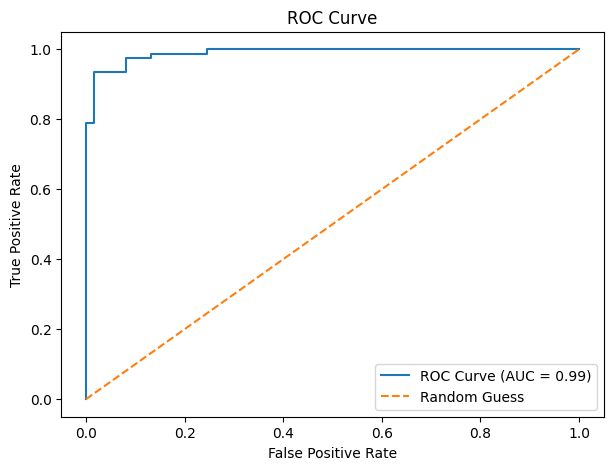

AUC Score: 0.9894


In [14]:
# Get prediction probabilities for the potholes class

y_probs = []

model.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)

        y_probs.extend(probabilities[:, 1].cpu().numpy())

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guess')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

print("AUC Score:", round(roc_auc, 4))

In [15]:
torch.save(model.state_dict(), "pothole_cnn.pth")

print("Model saved successfully!")

Model saved successfully!


Custom CNN: 127 correctly classified, 10 misclassified out of 137 validation images.


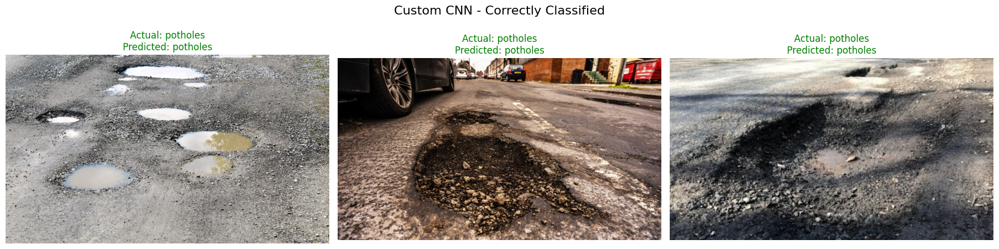

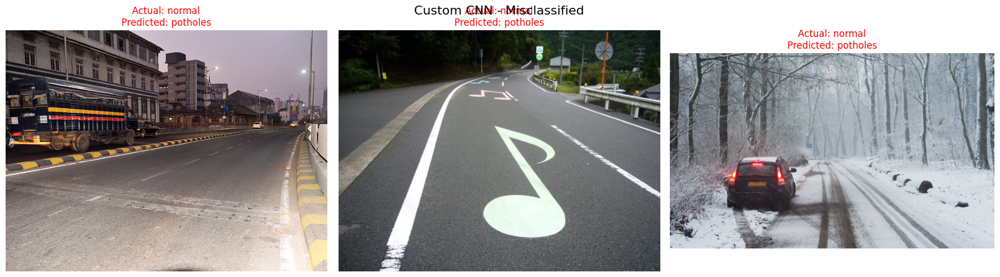

In [62]:
# Original-resolution prediction visuals for the Custom CNN
cnn_visual_results = visualize_original_predictions(
    model=model,
    validation_loader=val_loader,
    original_dataset=dataset,
    validation_indices=val_dataset.indices,
    class_names=class_names,
    model_name="Custom CNN",
    max_correct=3,
    max_misclassified=3
)


In [16]:
augmentation_transform = transforms.Compose([
    transforms.Resize((64, 64)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(10),

    transforms.ColorJitter(brightness=0.2, contrast=0.2),

    transforms.ToTensor()
])

In [17]:
from torch.utils.data import Subset

# Load the dataset with augmentation
augmented_dataset = datasets.ImageFolder(
    root=DATASET_PATH,
    transform=augmentation_transform
)
train_aug_dataset = Subset(
    augmented_dataset,
    train_dataset.indices
)

print("Original training images:", len(train_dataset))
print("Augmented training dataset:", len(train_aug_dataset))

Original training images: 544
Augmented training dataset: 544


In [18]:
augmented_train_loader = DataLoader(
    train_aug_dataset,
    batch_size=64,
    shuffle=True
)

print("Augmented DataLoader created successfully!")
print("Number of batches:", len(augmented_train_loader))

Augmented DataLoader created successfully!
Number of batches: 9


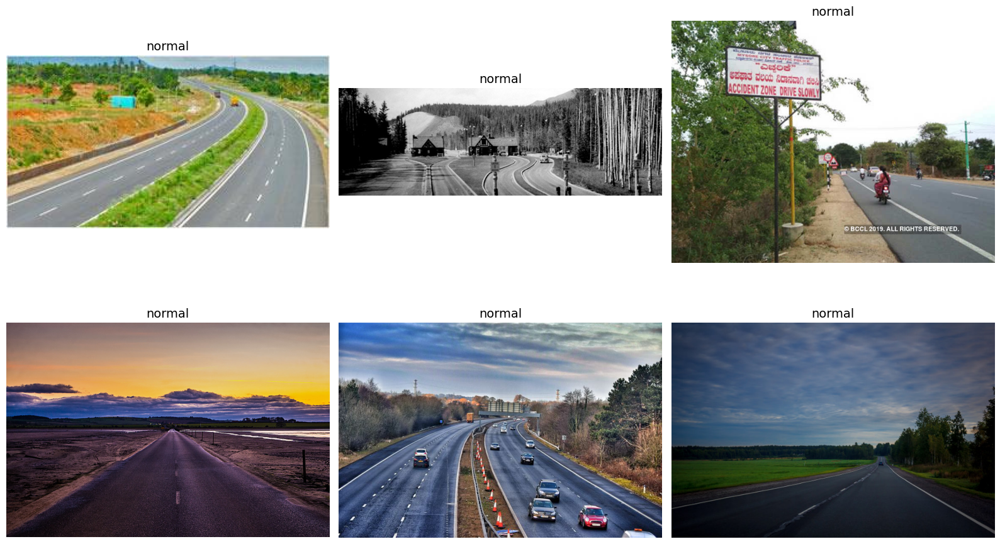

In [19]:
plt.figure(figsize=(16, 10))

for i in range(6):
    image_path, label = augmented_dataset.samples[i]

    img = Image.open(image_path).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(class_names[label], fontsize=14)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [20]:
resnet_train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor()
])

resnet_val_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

print("ResNet transforms created successfully!")

ResNet transforms created successfully!


In [21]:
# Create training and validation datasets
resnet_train_dataset = datasets.ImageFolder(
    root=DATASET_PATH,
    transform=resnet_train_transform
)

resnet_val_dataset = datasets.ImageFolder(
    root=DATASET_PATH,
    transform=resnet_val_transform
)

resnet_train_dataset = Subset(
    resnet_train_dataset,
    train_dataset.indices
)

resnet_val_dataset = Subset(
    resnet_val_dataset,
    val_dataset.indices
)

In [22]:
# CREATE DATALOADERS FOR RESNET18

resnet_train_loader = DataLoader(
    resnet_train_dataset,
    batch_size=32,
    shuffle=True
)

resnet_val_loader = DataLoader(
    resnet_val_dataset,
    batch_size=32,
    shuffle=False
)

print("ResNet18 DataLoaders created successfully!")

ResNet18 DataLoaders created successfully!


In [23]:
# CELL 9: LOAD PRETRAINED RESNET18 MODEL

from torchvision.models import resnet18, ResNet18_Weights

# Load ResNet18 with pretrained ImageNet weights
weights = ResNet18_Weights.DEFAULT
resnet_model = resnet18(weights=weights)

# Modify the final layer for our two classes
num_features = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(num_features, 2)

# Move model to available device
resnet_model = resnet_model.to(device)

print("Pretrained ResNet18 model loaded successfully!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 194MB/s]

Pretrained ResNet18 model loaded successfully!


In [24]:
# CONFIGURE RESNET18 LOSS FUNCTION AND OPTIMIZER

criterion_resnet = nn.CrossEntropyLoss()

optimizer_resnet = torch.optim.Adam(
    resnet_model.parameters(),
    lr=0.0001
)

print("ResNet18 loss function and optimizer configured!")

ResNet18 loss function and optimizer configured!


In [25]:
# TRAIN RESNET18 MODEL

import time

epochs_resnet = 5

train_losses_resnet = []
val_losses_resnet = []
train_accuracies_resnet = []
val_accuracies_resnet = []

start_time = time.time()

for epoch in range(epochs_resnet):

    # Training phase
    resnet_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in resnet_train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_resnet.zero_grad()

        outputs = resnet_model(images)
        loss = criterion_resnet(outputs, labels)

        loss.backward()
        optimizer_resnet.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(resnet_train_loader)
    train_accuracy = 100 * correct / total

    # Validation phase
    resnet_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in resnet_val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet_model(images)
            loss = criterion_resnet(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(resnet_val_loader)
    val_accuracy = 100 * val_correct / val_total

    train_losses_resnet.append(train_loss)
    val_losses_resnet.append(val_loss)
    train_accuracies_resnet.append(train_accuracy)
    val_accuracies_resnet.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs_resnet}] "
        f"Train Loss: {train_loss:.4f}, "
        f"Train Accuracy: {train_accuracy:.2f}%, "
        f"Val Loss: {val_loss:.4f}, "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

training_time_resnet = time.time() - start_time

print("ResNet18 training completed!")
print("Training time:", round(training_time_resnet, 2), "seconds")

Epoch [1/5] Train Loss: 0.2525, Train Accuracy: 88.60%, Val Loss: 0.0466, Val Accuracy: 98.54%
Epoch [2/5] Train Loss: 0.0428, Train Accuracy: 98.90%, Val Loss: 0.0179, Val Accuracy: 100.00%
Epoch [3/5] Train Loss: 0.0141, Train Accuracy: 99.82%, Val Loss: 0.0236, Val Accuracy: 99.27%
Epoch [4/5] Train Loss: 0.0192, Train Accuracy: 99.26%, Val Loss: 0.0201, Val Accuracy: 99.27%
Epoch [5/5] Train Loss: 0.0158, Train Accuracy: 99.63%, Val Loss: 0.0257, Val Accuracy: 100.00%
ResNet18 training completed!
Training time: 75.56 seconds


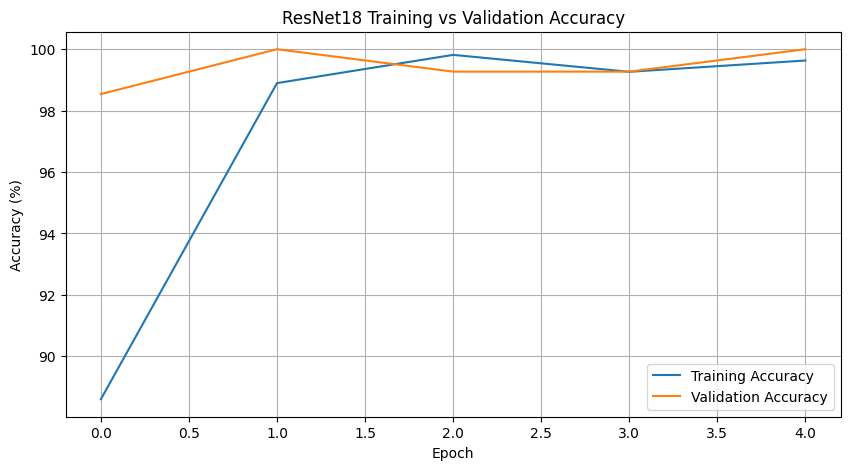

In [26]:
#  VISUALIZE RESNET18 ACCURACY

plt.figure(figsize=(10, 5))

plt.plot(train_accuracies_resnet, label='Training Accuracy')
plt.plot(val_accuracies_resnet, label='Validation Accuracy')

plt.title('ResNet18 Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.show()

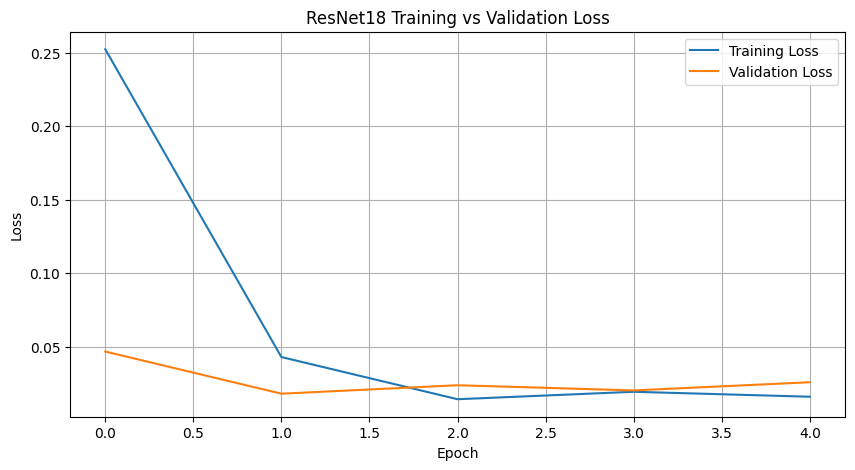

In [27]:
# VISUALIZE RESNET18 TRAINING AND VALIDATION LOSS

plt.figure(figsize=(10, 5))

plt.plot(train_losses_resnet, label='Training Loss')
plt.plot(val_losses_resnet, label='Validation Loss')

plt.title('ResNet18 Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

In [28]:
# EVALUATE RESNET18 USING CLASSIFICATION REPORT

y_true_resnet = []
y_pred_resnet = []

resnet_model.eval()

with torch.no_grad():
    for images, labels in resnet_val_loader:

        images = images.to(device)

        outputs = resnet_model(images)
        _, predicted = torch.max(outputs, 1)

        y_true_resnet.extend(labels.numpy())
        y_pred_resnet.extend(predicted.cpu().numpy())

print("RESNET18 CLASSIFICATION REPORT\n")

print(classification_report(
    y_true_resnet,
    y_pred_resnet,
    target_names=class_names
))

RESNET18 CLASSIFICATION REPORT

              precision    recall  f1-score   support

      normal       1.00      1.00      1.00        61
    potholes       1.00      1.00      1.00        76

    accuracy                           1.00       137
   macro avg       1.00      1.00      1.00       137
weighted avg       1.00      1.00      1.00       137



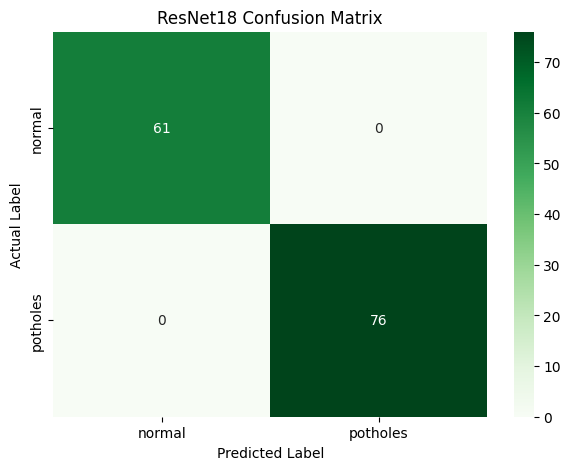

In [29]:
# CREATE RESNET18 CONFUSION MATRIX

cm_resnet = confusion_matrix(
    y_true_resnet,
    y_pred_resnet
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_resnet,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('ResNet18 Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

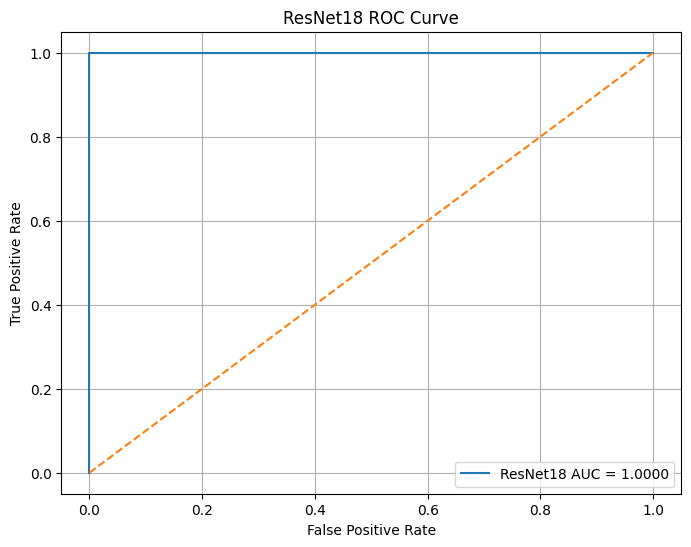

ResNet18 AUC: 1.0


In [30]:
#  CALCULATE RESNET18 ROC CURVE AND AUC

y_probs_resnet = []

resnet_model.eval()

with torch.no_grad():
    for images, labels in resnet_val_loader:

        images = images.to(device)

        outputs = resnet_model(images)

        probabilities = torch.softmax(outputs, dim=1)

        y_probs_resnet.extend(
            probabilities[:, 1].cpu().numpy()
        )

fpr_resnet, tpr_resnet, thresholds_resnet = roc_curve(
    y_true_resnet,
    y_probs_resnet
)

roc_auc_resnet = auc(fpr_resnet, tpr_resnet)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_resnet,
    tpr_resnet,
    label=f'ResNet18 AUC = {roc_auc_resnet:.4f}'
)

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ResNet18 ROC Curve')
plt.legend()
plt.grid(True)

plt.show()

print("ResNet18 AUC:", round(roc_auc_resnet, 4))

In [31]:
#  SAVE TRAINED RESNET18 MODEL

torch.save(
    resnet_model.state_dict(),
    "pothole_resnet18.pth"
)

print("ResNet18 model saved successfully!")

ResNet18 model saved successfully!


In [32]:
# CALCULATE PERFORMANCE METRICS FOR BOTH MODELS

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Custom CNN metrics
cnn_accuracy = accuracy_score(y_true, y_pred)
cnn_precision = precision_score(y_true, y_pred)
cnn_recall = recall_score(y_true, y_pred)
cnn_f1 = f1_score(y_true, y_pred)

# ResNet18 metrics
resnet_accuracy = accuracy_score(y_true_resnet, y_pred_resnet)
resnet_precision = precision_score(y_true_resnet, y_pred_resnet)
resnet_recall = recall_score(y_true_resnet, y_pred_resnet)
resnet_f1 = f1_score(y_true_resnet, y_pred_resnet)

print("Performance metrics calculated successfully!")

Performance metrics calculated successfully!


In [33]:
#  COMPARE CUSTOM CNN AND RESNET18 PERFORMANCE

import pandas as pd

comparison_data = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "AUC"],
    "Custom CNN": [
        cnn_accuracy,
        cnn_precision,
        cnn_recall,
        cnn_f1,
        roc_auc
    ],
    "ResNet18": [
        resnet_accuracy,
        resnet_precision,
        resnet_recall,
        resnet_f1,
        roc_auc_resnet
    ]
}

comparison_df = pd.DataFrame(comparison_data)

print("MODEL PERFORMANCE COMPARISON")
display(comparison_df.round(4))

MODEL PERFORMANCE COMPARISON


,Metric,Custom CNN,ResNet18
0,Accuracy,0.9270,1.0
1,Precision,0.8929,1.0
2,Recall,0.9868,1.0
3,F1-Score,0.9375,1.0
4,AUC,0.9894,1.0


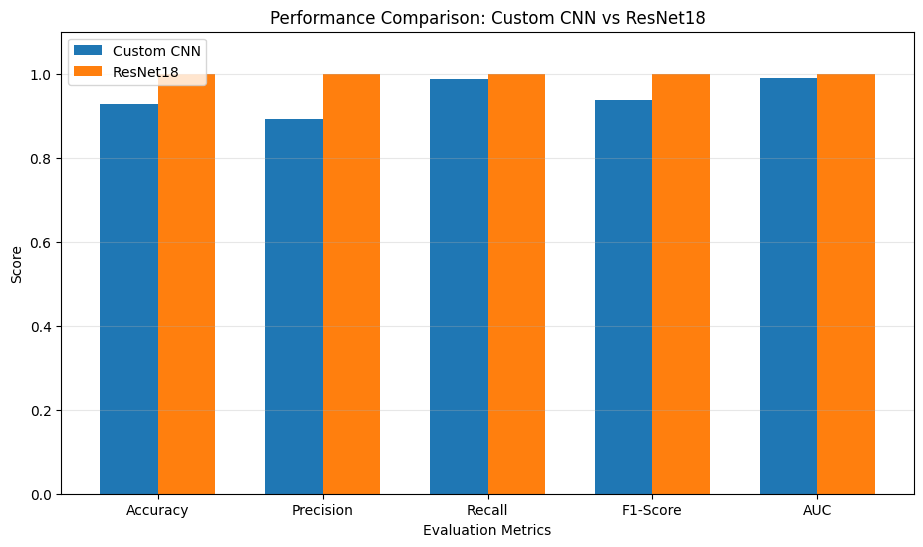

In [34]:
#  VISUALIZE CUSTOM CNN VS RESNET18 COMPARISON

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "AUC"]

cnn_scores = [
    cnn_accuracy,
    cnn_precision,
    cnn_recall,
    cnn_f1,
    roc_auc
]

resnet_scores = [
    resnet_accuracy,
    resnet_precision,
    resnet_recall,
    resnet_f1,
    roc_auc_resnet
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(x - width/2, cnn_scores, width, label="Custom CNN")
plt.bar(x + width/2, resnet_scores, width, label="ResNet18")

plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("Performance Comparison: Custom CNN vs ResNet18")

plt.xticks(x, metrics)
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

In [35]:
# DEFINE FUNCTION TO PREDICT NEW ROAD IMAGES

from PIL import Image

def predict_pothole(image_path):
    img = Image.open(image_path).convert("RGB")
    input_tensor = resnet_val_transform(img).unsqueeze(0).to(device)
    resnet_model.eval()

    with torch.no_grad():
        output = resnet_model(input_tensor)
        probabilities = torch.softmax(output, dim=1)

        confidence, predicted_class = torch.max(probabilities, 1)

    prediction = class_names[predicted_class.item()]

    plt.figure(figsize=(7, 5))
    plt.imshow(img)
    plt.title(
        f"Prediction: {prediction}\n"
        f"Confidence: {confidence.item() * 100:.2f}%"
    )
    plt.axis("off")
    plt.show()

    return prediction

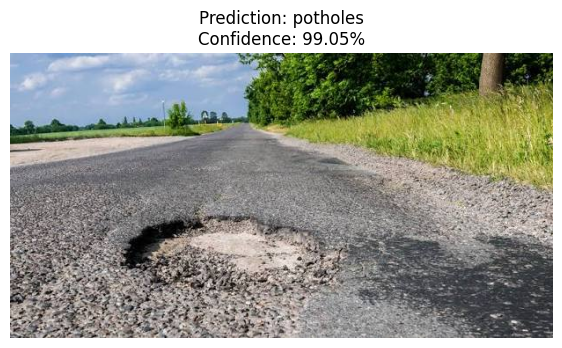

Final Prediction: potholes


In [36]:
# TEST RESNET18 ON A NEW ROAD IMAGE

image_path = "/kaggle/input/datasets/singusiri/test2img/test2.jpg"

prediction = predict_pothole(image_path)

print("Final Prediction:", prediction)


Testing image: Dirtroadpotholes.JPG


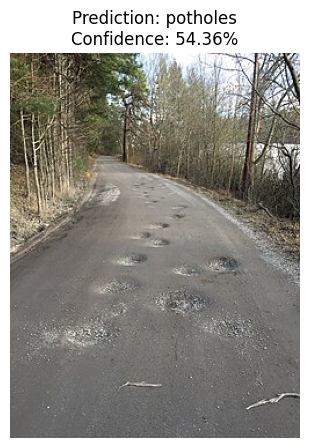

Predicted class: potholes

Testing image: Kailua_pothole.jpg


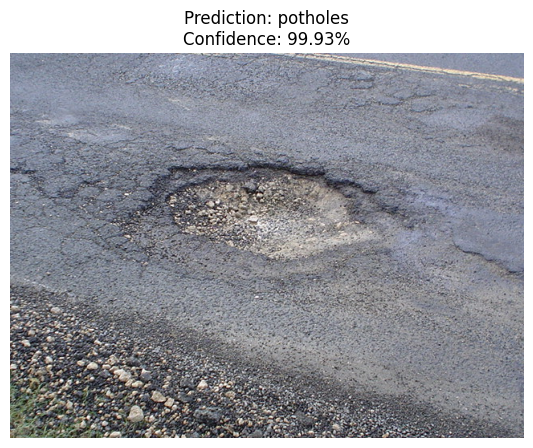

Predicted class: potholes

Testing image: images.jpg


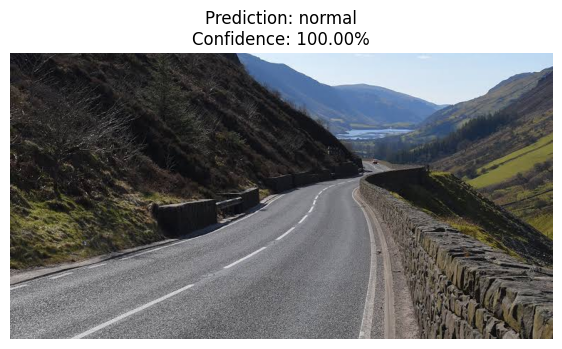

Predicted class: normal

Testing image: p0h6xdy6.jpg


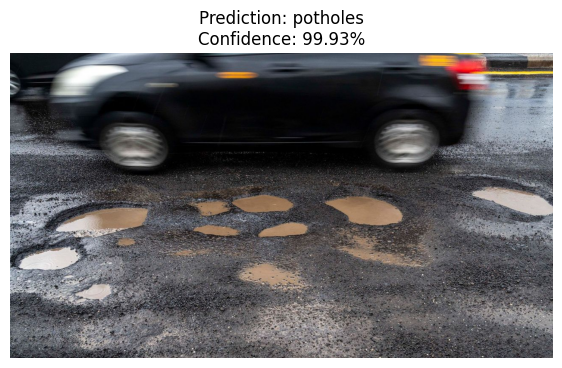

Predicted class: potholes

Testing image: roads-slide-in_San-Marco-FL-Road-Gordon-Chaffin.jpg


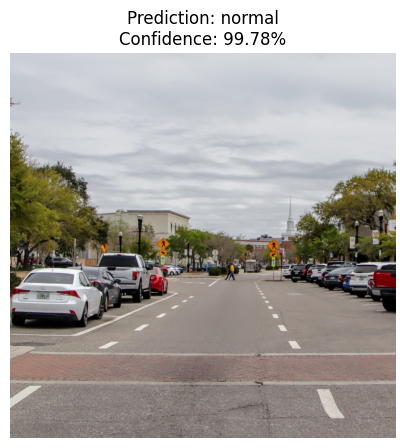

Predicted class: normal

Testing image: scenic-roads-3.jpg


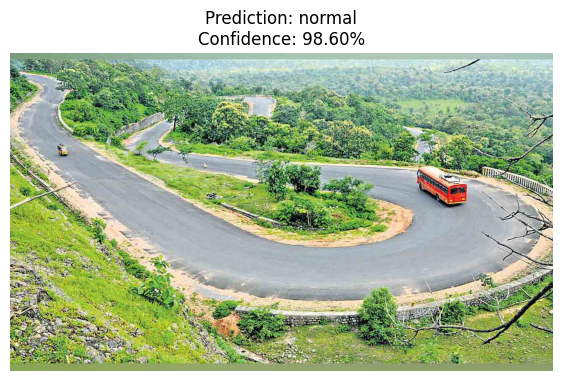

Predicted class: normal


In [37]:
#TEST RESNET18 ON MULTIPLE UNSEEN IMAGES

import os

test_folder = "/kaggle/input/datasets/singusiri/tesing-imgs-resnet"

supported_formats = (".jpg", ".jpeg", ".png")

for file in os.listdir(test_folder):

    if file.lower().endswith(supported_formats):

        image_path = os.path.join(test_folder, file)

        print("\nTesting image:", file)

        prediction = predict_pothole(image_path)

        print("Predicted class:", prediction)

ResNet18: 137 correctly classified, 0 misclassified out of 137 validation images.


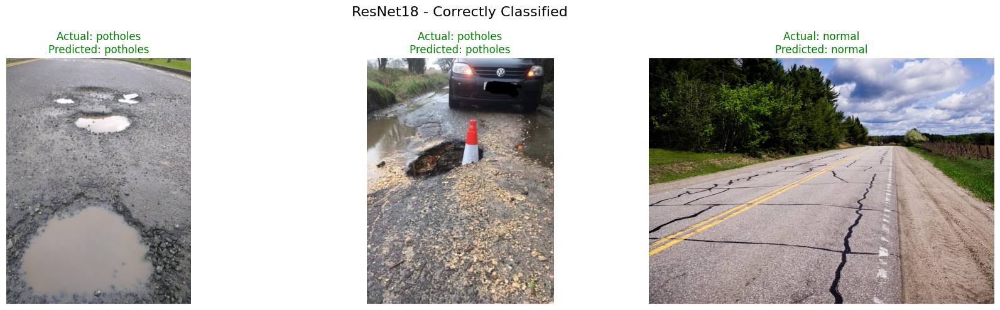

No misclassified images to display for ResNet18.


In [64]:
# RESNET18 - CLASSIFIED AND MISCLASSIFIED IMAGES

lstm_visual_results = visualize_original_predictions(
    model=resnet_model,
    validation_loader=resnet_val_loader,
    original_dataset=dataset,
    validation_indices=val_dataset.indices,
    class_names=class_names,
    model_name="ResNet18",
    max_correct=3,
    max_misclassified=3
)

In [38]:
# FINAL MODEL COMPARISON SUMMARY

print("POTHOLE CLASSIFICATION PROJECT RESULTS")

print("\nMODEL 1: CUSTOM CNN")
print(f"Accuracy  : {cnn_accuracy * 100:.2f}%")
print(f"Precision : {cnn_precision * 100:.2f}%")
print(f"Recall    : {cnn_recall * 100:.2f}%")
print(f"F1-Score  : {cnn_f1 * 100:.2f}%")
print(f"AUC       : {roc_auc:.4f}")

print("\nMODEL 2: RESNET18")
print(f"Accuracy  : {resnet_accuracy * 100:.2f}%")
print(f"Precision : {resnet_precision * 100:.2f}%")
print(f"Recall    : {resnet_recall * 100:.2f}%")
print(f"F1-Score  : {resnet_f1 * 100:.2f}%")
print(f"AUC       : {roc_auc_resnet:.4f}")

print("\nBEST OVERALL MODEL: RESNET18")

POTHOLE CLASSIFICATION PROJECT RESULTS

MODEL 1: CUSTOM CNN
Accuracy  : 92.70%
Precision : 89.29%
Recall    : 98.68%
F1-Score  : 93.75%
AUC       : 0.9894

MODEL 2: RESNET18
Accuracy  : 100.00%
Precision : 100.00%
Recall    : 100.00%
F1-Score  : 100.00%
AUC       : 1.0000

BEST OVERALL MODEL: RESNET18


In [39]:
#  VERIFY EXISTING CUSTOM CNN RESULTS

print("CUSTOM CNN PREVIOUS EVALUATION")

print("Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

CUSTOM CNN PREVIOUS EVALUATION
Accuracy: 92.7 %

Classification Report:

              precision    recall  f1-score   support

      normal       0.98      0.85      0.91        61
    potholes       0.89      0.99      0.94        76

    accuracy                           0.93       137
   macro avg       0.94      0.92      0.92       137
weighted avg       0.93      0.93      0.93       137



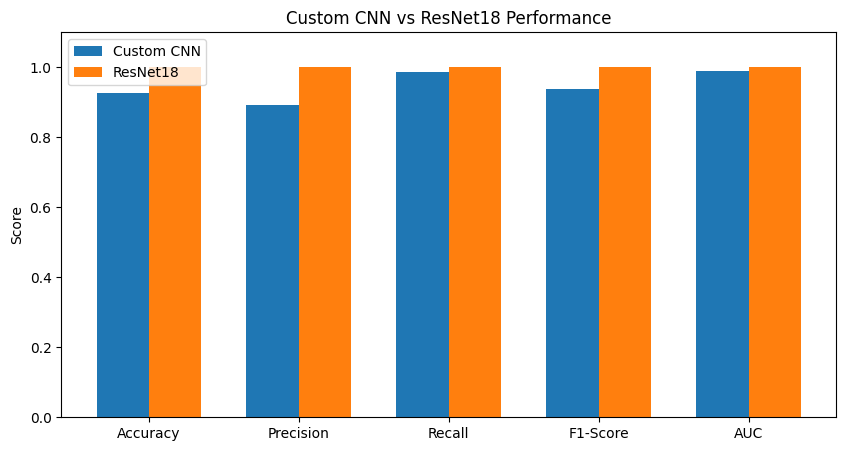

In [40]:
# MODEL PERFORMANCE COMPARISON GRAPH

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "AUC"]

plt.figure(figsize=(10, 5))

x = np.arange(len(metrics))
width = 0.35

plt.bar(x - width/2, comparison_data["Custom CNN"], width, label="Custom CNN")
plt.bar(x + width/2, comparison_data["ResNet18"], width, label="ResNet18")

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("Custom CNN vs ResNet18 Performance")
plt.ylim(0, 1.1)
plt.legend()
plt.show()

In [41]:
torch.save(resnet_model.state_dict(), "final_pothole_resnet18.pth")
print("Final ResNet18 model saved successfully!")

Final ResNet18 model saved successfully!


In [42]:
# CELL 32: CHECK OPTIMIZER EXPERIMENT REQUIREMENTS

print("Training loader:", len(train_loader))
print("Validation loader:", len(val_loader))
print("CNN architecture:", CNN)
print("Device:", device)

Training loader: 9
Validation loader: 3
CNN architecture: <class '__main__.CNN'>
Device: cuda


In [43]:
# CELL 42: IMPORTS AND EXPERIMENT CONFIGURATION

import os
import copy
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torch.utils.data import (
    DataLoader, Dataset, Subset, ConcatDataset, TensorDataset
)

from torchvision import datasets, transforms
from torchvision.utils import save_image, make_grid

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Experiment configuration
IMAGE_SIZE = 64
NUM_CLASSES = len(dataset.classes)
CLASS_NAMES = dataset.classes

BATCH_SIZE = 32
NUM_EPOCHS = 10
LEARNING_RATE = 0.001

CHECKPOINT_DIR = "pothole_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Device:", device)
print("Classes:", CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)
print("Checkpoint directory:", CHECKPOINT_DIR)

Device: cuda
Classes: ['normal', 'potholes']
Number of classes: 2
Checkpoint directory: pothole_checkpoints


In [45]:
# CELL 43: COMMON TRAINING AND EVALUATION FUNCTION

def run_experiment(
    model,
    train_loader,
    val_loader,
    model_name,
    optimizer,
    epochs=NUM_EPOCHS
):

    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    start_time = time.time()

    for epoch in range(epochs):

        # ---------------- TRAINING ----------------

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

        train_loss = running_loss / total
        train_accuracy = 100 * correct / total

        # ---------------- VALIDATION ----------------

        model.eval()

        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * labels.size(0)

                predictions = outputs.argmax(dim=1)

                val_total += labels.size(0)
                val_correct += (
                    predictions == labels
                ).sum().item()

        val_loss = val_running_loss / val_total
        val_accuracy = 100 * val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"{model_name} | "
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Acc: {val_accuracy:.2f}%"
        )

    training_time = time.time() - start_time

    # ---------------- FINAL PREDICTIONS ----------------

    model.eval()

    y_true = []
    y_pred = []
    y_probs = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)

            outputs = model(images)

            probabilities = torch.softmax(outputs, dim=1)

            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())
            y_probs.extend(probabilities.cpu().numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_probs = np.array(y_probs)

    # ---------------- CLASSIFICATION METRICS ----------------

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred, average="binary", zero_division=0
    )

    recall = recall_score(
        y_true, y_pred, average="binary", zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred, average="binary", zero_division=0
    )

    # Class index 1 is treated as the positive class.
    # Check CLASS_NAMES before interpreting positive-class metrics.

    fpr, tpr, thresholds = roc_curve(
        y_true, y_probs[:, 1]
    )

    roc_auc = auc(fpr, tpr)

    # ---------------- ACCURACY CURVE ----------------

    plt.figure(figsize=(8, 5))

    plt.plot(
        history["train_accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.title(f"{model_name} - Accuracy Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.legend()
    plt.grid(True)

    plt.savefig(
        f"{CHECKPOINT_DIR}/{model_name}_accuracy.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # ---------------- LOSS CURVE ----------------

    plt.figure(figsize=(8, 5))

    plt.plot(
        history["train_loss"],
        label="Training Loss"
    )

    plt.plot(
        history["val_loss"],
        label="Validation Loss"
    )

    plt.title(f"{model_name} - Loss Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)

    plt.savefig(
        f"{CHECKPOINT_DIR}/{model_name}_loss.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # ---------------- CONFUSION MATRIX ----------------

    cm = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.savefig(
        f"{CHECKPOINT_DIR}/{model_name}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # ---------------- ROC CURVE ----------------

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr,
        tpr,
        label=f"AUC = {roc_auc:.4f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random Classifier"
    )

    plt.title(f"{model_name} - ROC Curve")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.grid(True)

    plt.savefig(
        f"{CHECKPOINT_DIR}/{model_name}_roc.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # ---------------- CLASSIFICATION REPORT ----------------

    print(f"\n{model_name} CLASSIFICATION REPORT\n")

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=CLASS_NAMES,
            zero_division=0
        )
    )

    # ---------------- SAVE CHECKPOINT ----------------

    checkpoint_path = (
        f"{CHECKPOINT_DIR}/{model_name}.pth"
    )

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "class_names": CLASS_NAMES,
            "history": history,
            "accuracy": accuracy,
            "optimizer": optimizer.__class__.__name__
        },
        checkpoint_path
    )

    print("Checkpoint saved:", checkpoint_path)

    # ---------------- RETURN RESULTS ----------------

    results = {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "AUC": roc_auc,
        "Training Time": training_time,
        "History": history,
        "Y True": y_true,
        "Y Pred": y_pred,
        "Y Probabilities": y_probs
    }

    return results


========== CNN WITH ADAM ==========
CNN_Adam | Epoch 1/10 | Train Loss: 2.5274 | Val Loss: 1.0455 | Train Acc: 56.43% | Val Acc: 55.47%
CNN_Adam | Epoch 2/10 | Train Loss: 0.5952 | Val Loss: 0.9119 | Train Acc: 81.43% | Val Acc: 61.31%
CNN_Adam | Epoch 3/10 | Train Loss: 0.3649 | Val Loss: 0.9040 | Train Acc: 85.85% | Val Acc: 64.23%
CNN_Adam | Epoch 4/10 | Train Loss: 0.3041 | Val Loss: 0.4460 | Train Acc: 87.87% | Val Acc: 79.56%
CNN_Adam | Epoch 5/10 | Train Loss: 0.2420 | Val Loss: 0.2753 | Train Acc: 89.34% | Val Acc: 88.32%
CNN_Adam | Epoch 6/10 | Train Loss: 0.1986 | Val Loss: 0.3488 | Train Acc: 92.10% | Val Acc: 83.94%
CNN_Adam | Epoch 7/10 | Train Loss: 0.2230 | Val Loss: 0.1778 | Train Acc: 90.26% | Val Acc: 92.70%
CNN_Adam | Epoch 8/10 | Train Loss: 0.2110 | Val Loss: 0.2939 | Train Acc: 91.91% | Val Acc: 90.51%
CNN_Adam | Epoch 9/10 | Train Loss: 0.1802 | Val Loss: 0.1610 | Train Acc: 93.01% | Val Acc: 92.70%
CNN_Adam | Epoch 10/10 | Train Loss: 0.1562 | Val Loss: 0.1822 

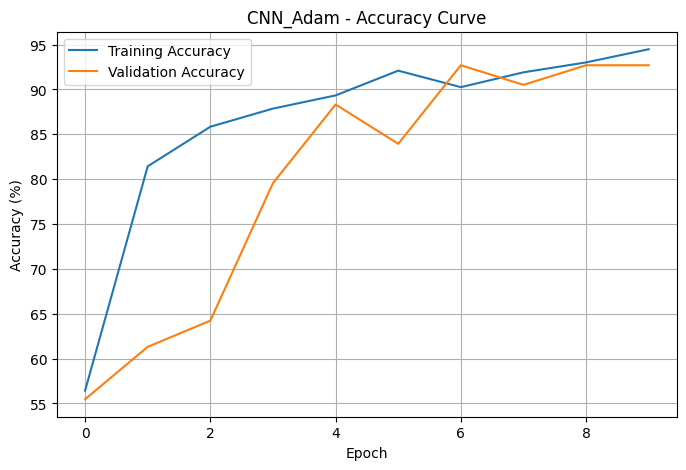

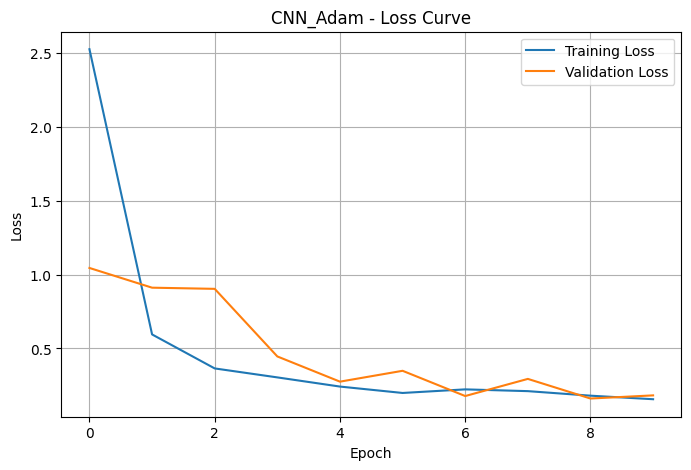

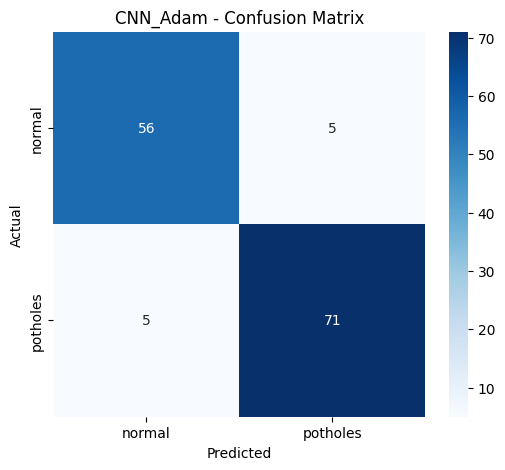

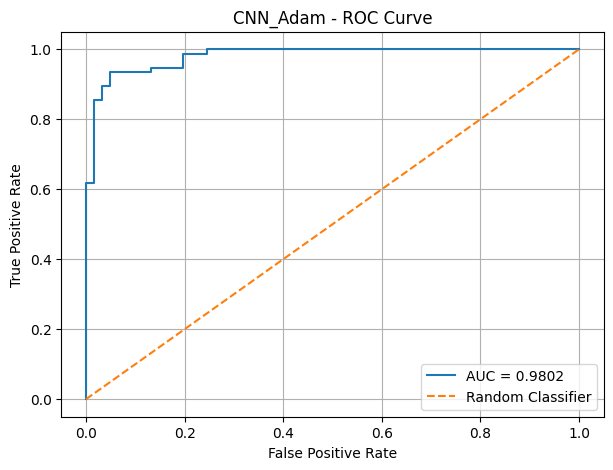


CNN_Adam CLASSIFICATION REPORT

              precision    recall  f1-score   support

      normal       0.92      0.92      0.92        61
    potholes       0.93      0.93      0.93        76

    accuracy                           0.93       137
   macro avg       0.93      0.93      0.93       137
weighted avg       0.93      0.93      0.93       137

Checkpoint saved: pothole_checkpoints/CNN_Adam.pth

========== CNN WITH SGD ==========
CNN_SGD | Epoch 1/10 | Train Loss: 0.5745 | Val Loss: 0.6646 | Train Acc: 67.83% | Val Acc: 62.04%
CNN_SGD | Epoch 2/10 | Train Loss: 0.3976 | Val Loss: 0.5466 | Train Acc: 83.64% | Val Acc: 67.88%
CNN_SGD | Epoch 3/10 | Train Loss: 0.3732 | Val Loss: 0.4095 | Train Acc: 86.95% | Val Acc: 90.51%
CNN_SGD | Epoch 4/10 | Train Loss: 0.2351 | Val Loss: 0.6663 | Train Acc: 89.34% | Val Acc: 65.69%
CNN_SGD | Epoch 5/10 | Train Loss: 0.2321 | Val Loss: 0.3142 | Train Acc: 89.71% | Val Acc: 85.40%
CNN_SGD | Epoch 6/10 | Train Loss: 0.1904 | Val Loss: 0.59

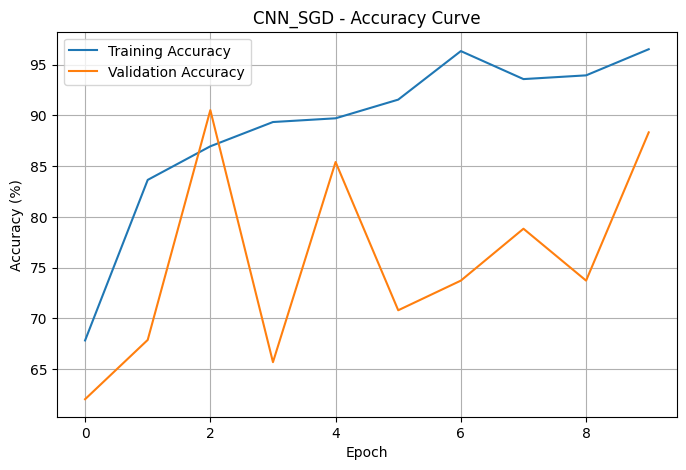

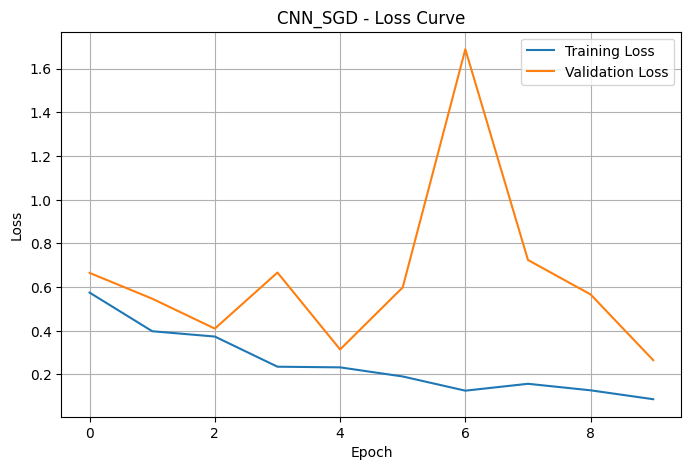

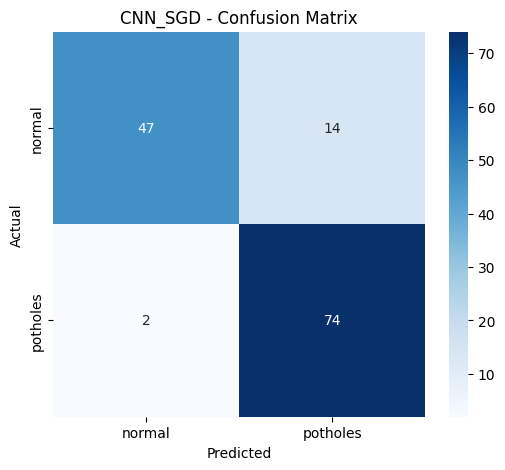

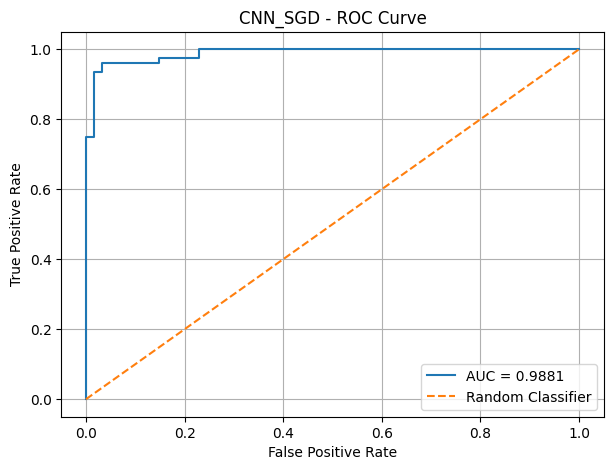


CNN_SGD CLASSIFICATION REPORT

              precision    recall  f1-score   support

      normal       0.96      0.77      0.85        61
    potholes       0.84      0.97      0.90        76

    accuracy                           0.88       137
   macro avg       0.90      0.87      0.88       137
weighted avg       0.89      0.88      0.88       137

Checkpoint saved: pothole_checkpoints/CNN_SGD.pth

========== CNN WITH RMSPROP ==========
CNN_RMSprop | Epoch 1/10 | Train Loss: 17.8801 | Val Loss: 4.3657 | Train Acc: 66.18% | Val Acc: 55.47%
CNN_RMSprop | Epoch 2/10 | Train Loss: 1.2028 | Val Loss: 4.0344 | Train Acc: 80.70% | Val Acc: 55.47%
CNN_RMSprop | Epoch 3/10 | Train Loss: 0.6495 | Val Loss: 1.2246 | Train Acc: 83.82% | Val Acc: 59.85%
CNN_RMSprop | Epoch 4/10 | Train Loss: 0.5350 | Val Loss: 1.1823 | Train Acc: 83.82% | Val Acc: 68.61%
CNN_RMSprop | Epoch 5/10 | Train Loss: 0.3772 | Val Loss: 0.5005 | Train Acc: 86.21% | Val Acc: 75.91%
CNN_RMSprop | Epoch 6/10 | Train Lo

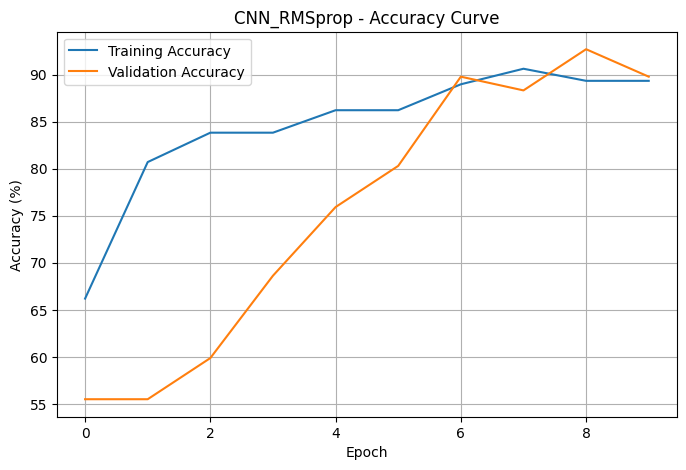

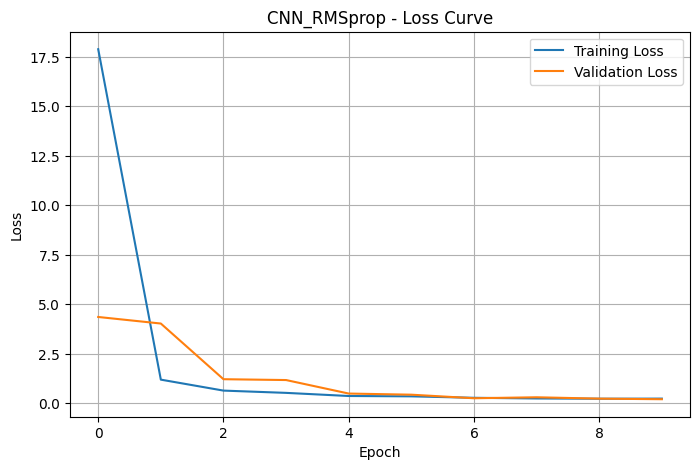

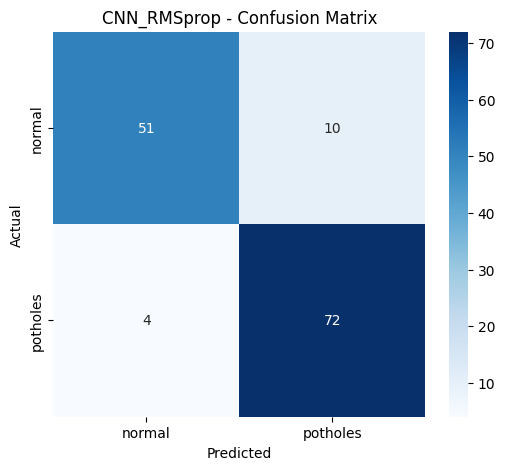

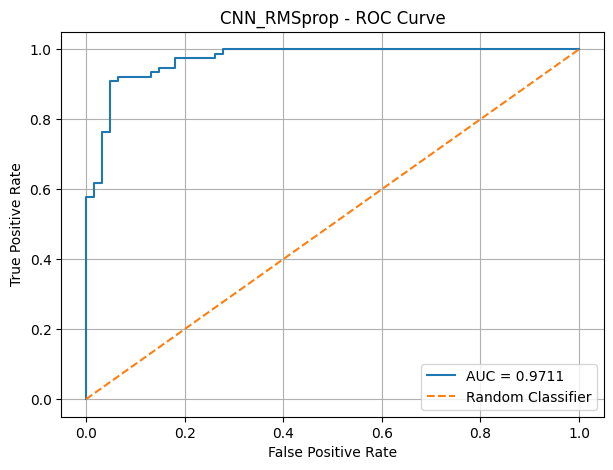


CNN_RMSprop CLASSIFICATION REPORT

              precision    recall  f1-score   support

      normal       0.93      0.84      0.88        61
    potholes       0.88      0.95      0.91        76

    accuracy                           0.90       137
   macro avg       0.90      0.89      0.90       137
weighted avg       0.90      0.90      0.90       137

Checkpoint saved: pothole_checkpoints/CNN_RMSprop.pth

All optimizer experiments completed!


In [47]:
# CELL 44: CNN OPTIMIZER COMPARISON

optimizer_results = []

# EXPERIMENT 1: ADAM

print("\n========== CNN WITH ADAM ==========")

cnn_adam = CNN().to(device)

adam_optimizer = optim.Adam(
    cnn_adam.parameters(),
    lr=0.001
)

adam_results = run_experiment(
    model=cnn_adam,
    train_loader=train_loader,
    val_loader=val_loader,
    model_name="CNN_Adam",
    optimizer=adam_optimizer,
    epochs=NUM_EPOCHS
)

optimizer_results.append(adam_results)


# EXPERIMENT 2: SGD

print("\n========== CNN WITH SGD ==========")

cnn_sgd = CNN().to(device)

sgd_optimizer = optim.SGD(
    cnn_sgd.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=1e-4
)

sgd_results = run_experiment(
    model=cnn_sgd,
    train_loader=train_loader,
    val_loader=val_loader,
    model_name="CNN_SGD",
    optimizer=sgd_optimizer,
    epochs=NUM_EPOCHS
)

optimizer_results.append(sgd_results)


# EXPERIMENT 3: RMSPROP

print("\n========== CNN WITH RMSPROP ==========")

cnn_rmsprop = CNN().to(device)

rmsprop_optimizer = optim.RMSprop(
    cnn_rmsprop.parameters(),
    lr=0.001,
    alpha=0.99,
    momentum=0.0
)

rmsprop_results = run_experiment(
    model=cnn_rmsprop,
    train_loader=train_loader,
    val_loader=val_loader,
    model_name="CNN_RMSprop",
    optimizer=rmsprop_optimizer,
    epochs=NUM_EPOCHS
)

optimizer_results.append(rmsprop_results)

print("\nAll optimizer experiments completed!")

OPTIMIZER PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,AUC,Training Time
0,CNN_Adam,0.9270,0.9342,0.9342,0.9342,0.9802,130.6100
1,CNN_SGD,0.8832,0.8409,0.9737,0.9024,0.9881,131.4226
2,CNN_RMSprop,0.8978,0.8780,0.9474,0.9114,0.9711,131.1896


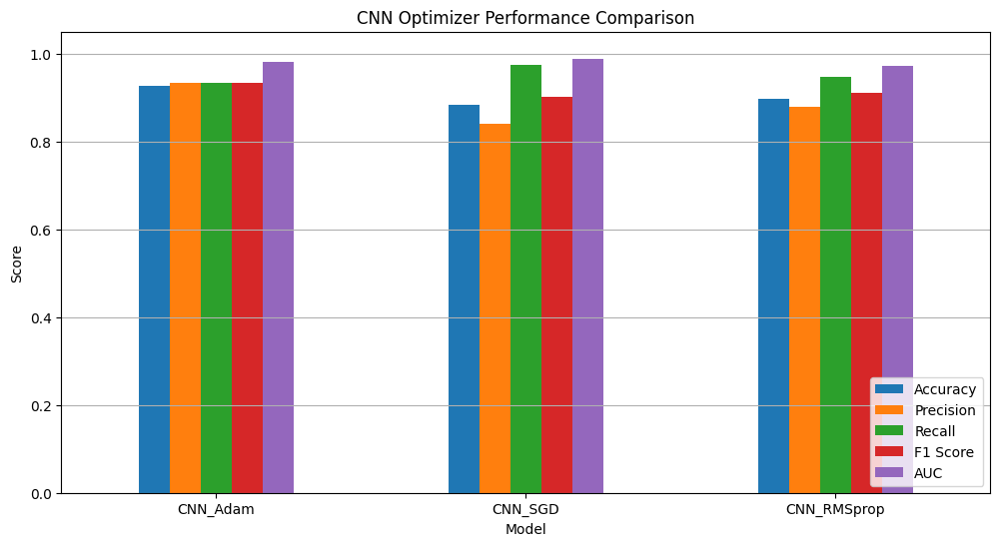

In [48]:
# CELL 45: COMPARE OPTIMIZERS

optimizer_df = pd.DataFrame([
    {
        key: result[key]
        for key in [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score",
            "AUC",
            "Training Time"
        ]
    }
    for result in optimizer_results
])

print("OPTIMIZER PERFORMANCE COMPARISON")

display(optimizer_df.round(4))

# Comparison graph

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "AUC"
]

optimizer_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("CNN Optimizer Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.legend(loc="lower right")
plt.show()

CNN - Adam: 127 correctly classified, 10 misclassified out of 137 validation images.


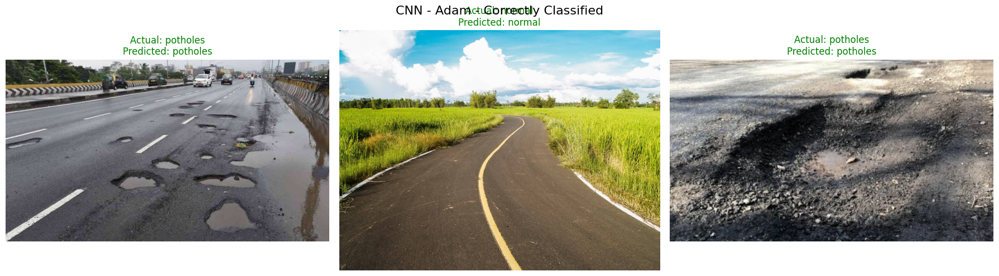

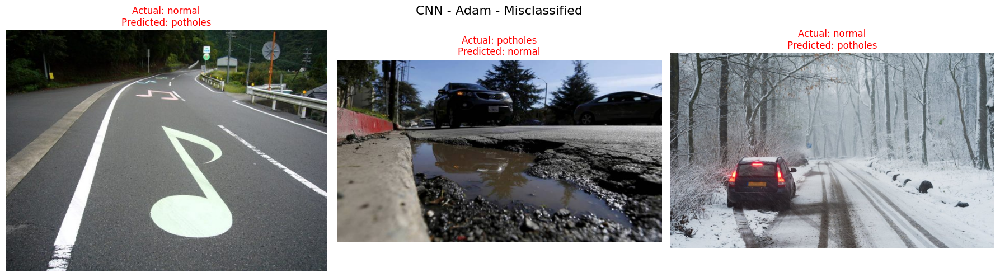

In [67]:
adam_visual_results = visualize_original_predictions(
    model=cnn_adam,
    validation_loader=val_loader,
    original_dataset=dataset,
    validation_indices=val_dataset.indices,
    class_names=class_names,
    model_name="CNN - Adam",
    max_correct=3,
    max_misclassified=3
)

CNN - SGD: 121 correctly classified, 16 misclassified out of 137 validation images.


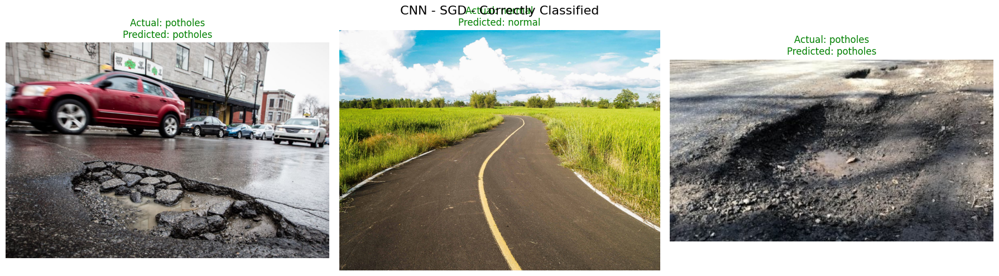

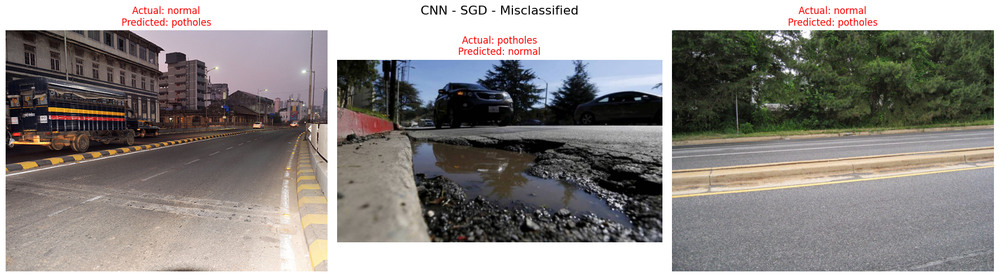

In [68]:
sgd_visual_results = visualize_original_predictions(
    model=cnn_sgd,
    validation_loader=val_loader,
    original_dataset=dataset,
    validation_indices=val_dataset.indices,
    class_names=class_names,
    model_name="CNN - SGD",
    max_correct=3,
    max_misclassified=3
)

CNN - RMSprop: 123 correctly classified, 14 misclassified out of 137 validation images.


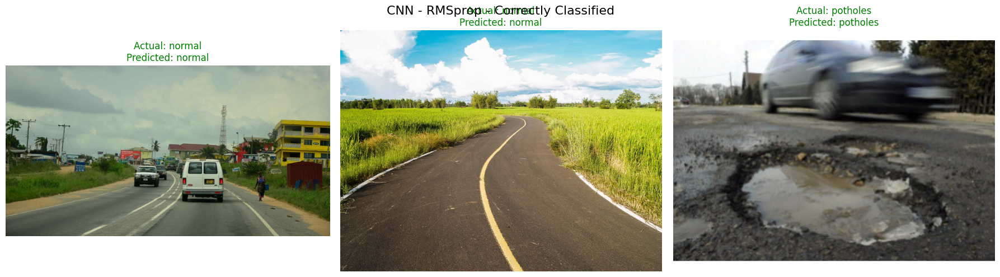

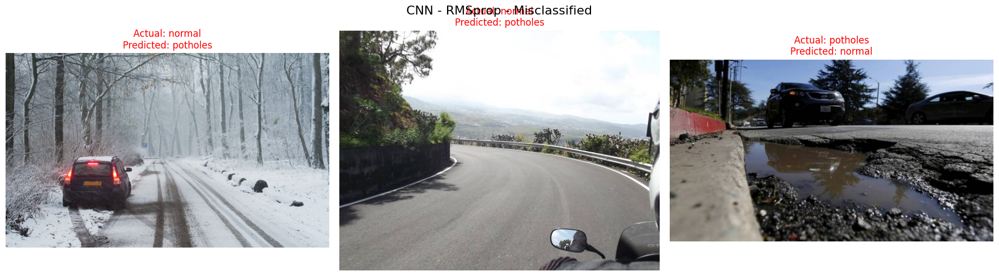

In [70]:
rmsprop_visual_results = visualize_original_predictions(
    model=	cnn_rmsprop,
    validation_loader=val_loader,
    original_dataset=dataset,
    validation_indices=val_dataset.indices,
    class_names=class_names,
    model_name="CNN - RMSprop",
    max_correct=3,
    max_misclassified=3
)

In [49]:
# CELL 46: ADVANCED DATA AUGMENTATION

advanced_train_transform = transforms.Compose([

    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(degrees=15),

    transforms.ColorJitter(
        brightness=0.25,
        contrast=0.25,
        saturation=0.2,
        hue=0.05
    ),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.08, 0.08),
        scale=(0.9, 1.1)
    ),

    transforms.ToTensor()

])

normal_val_transform = transforms.Compose([

    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()

])

print("Advanced augmentation transforms created!")

Advanced augmentation transforms created!


In [51]:
# CELL 47: AUGMENTED DATASET AND DATALOADERS

augmented_dataset = datasets.ImageFolder(
    root=DATASET_PATH,
    transform=advanced_train_transform
)

normal_dataset = datasets.ImageFolder(
    root=DATASET_PATH,
    transform=normal_val_transform
)

augmented_train_dataset = Subset(
    augmented_dataset,
    train_dataset.indices
)

normal_validation_dataset = Subset(
    normal_dataset,
    val_dataset.indices
)

augmented_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

normal_val_loader = DataLoader(
    normal_validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Original training images:", len(train_dataset))
print("Augmented training images:", len(augmented_train_dataset))
print("Validation images:", len(normal_validation_dataset))

Original training images: 544
Augmented training images: 544
Validation images: 137


CNN_Advanced_Augmentation | Epoch 1/10 | Train Loss: 1.7966 | Val Loss: 0.8037 | Train Acc: 60.11% | Val Acc: 61.31%
CNN_Advanced_Augmentation | Epoch 2/10 | Train Loss: 0.5619 | Val Loss: 0.6080 | Train Acc: 76.65% | Val Acc: 70.07%
CNN_Advanced_Augmentation | Epoch 3/10 | Train Loss: 0.3750 | Val Loss: 0.2933 | Train Acc: 84.56% | Val Acc: 87.59%
CNN_Advanced_Augmentation | Epoch 4/10 | Train Loss: 0.3199 | Val Loss: 0.2783 | Train Acc: 87.13% | Val Acc: 88.32%
CNN_Advanced_Augmentation | Epoch 5/10 | Train Loss: 0.3269 | Val Loss: 0.4165 | Train Acc: 86.03% | Val Acc: 83.21%
CNN_Advanced_Augmentation | Epoch 6/10 | Train Loss: 0.3434 | Val Loss: 0.2502 | Train Acc: 85.48% | Val Acc: 91.97%
CNN_Advanced_Augmentation | Epoch 7/10 | Train Loss: 0.3299 | Val Loss: 0.2409 | Train Acc: 86.40% | Val Acc: 90.51%
CNN_Advanced_Augmentation | Epoch 8/10 | Train Loss: 0.2916 | Val Loss: 0.3144 | Train Acc: 88.42% | Val Acc: 86.13%
CNN_Advanced_Augmentation | Epoch 9/10 | Train Loss: 0.3006 | Va

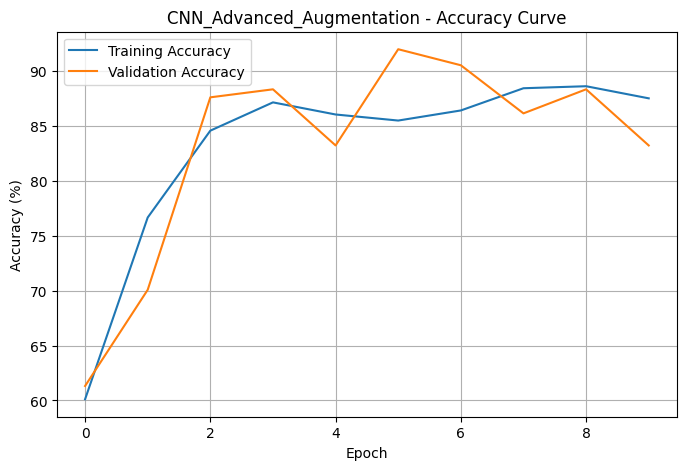

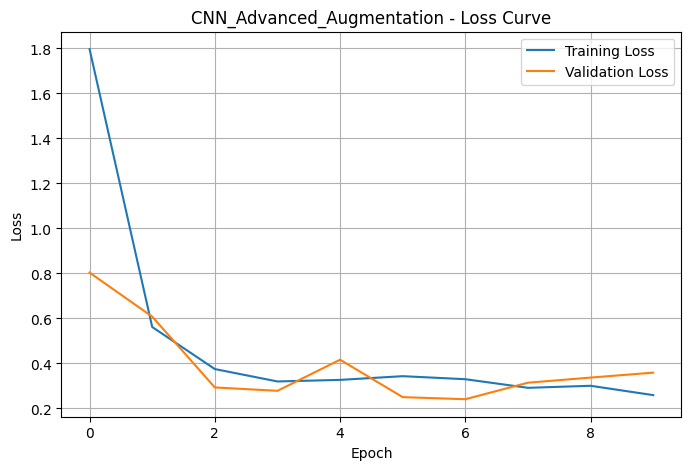

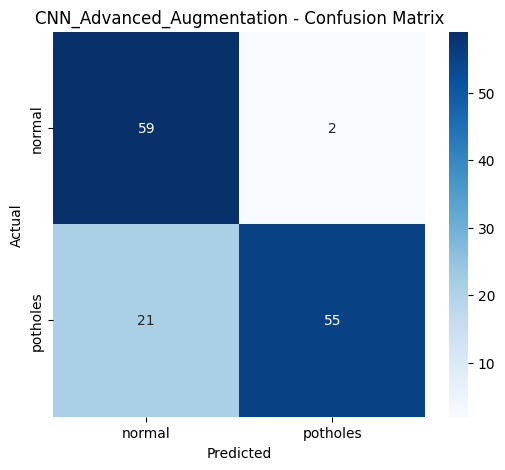

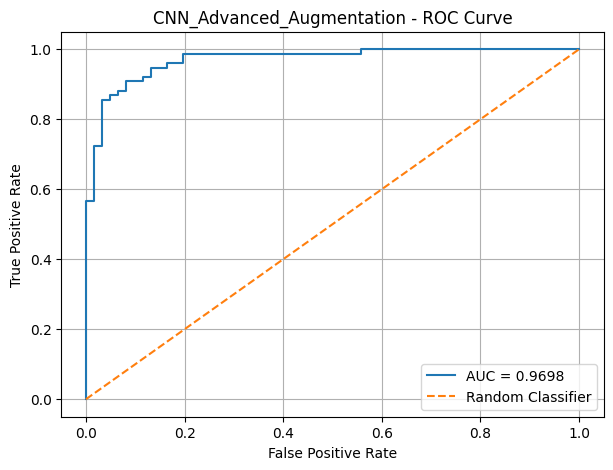


CNN_Advanced_Augmentation CLASSIFICATION REPORT

              precision    recall  f1-score   support

      normal       0.74      0.97      0.84        61
    potholes       0.96      0.72      0.83        76

    accuracy                           0.83       137
   macro avg       0.85      0.85      0.83       137
weighted avg       0.86      0.83      0.83       137

Checkpoint saved: pothole_checkpoints/CNN_Advanced_Augmentation.pth
Data augmentation experiment completed!


In [52]:
# CELL 48: CNN WITH DATA AUGMENTATION

cnn_augmented = CNN().to(device)

augmentation_optimizer = optim.Adam(
    cnn_augmented.parameters(),
    lr=0.001
)

augmentation_results = run_experiment(
    model=cnn_augmented,
    train_loader=augmented_train_loader,
    val_loader=normal_val_loader,
    model_name="CNN_Advanced_Augmentation",
    optimizer=augmentation_optimizer,
    epochs=NUM_EPOCHS
)

print("Data augmentation experiment completed!")

CNN - Augmentation: 114 correctly classified, 23 misclassified out of 137 validation images.


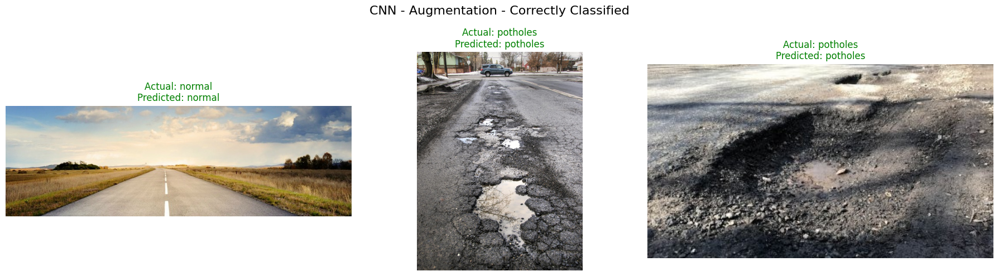

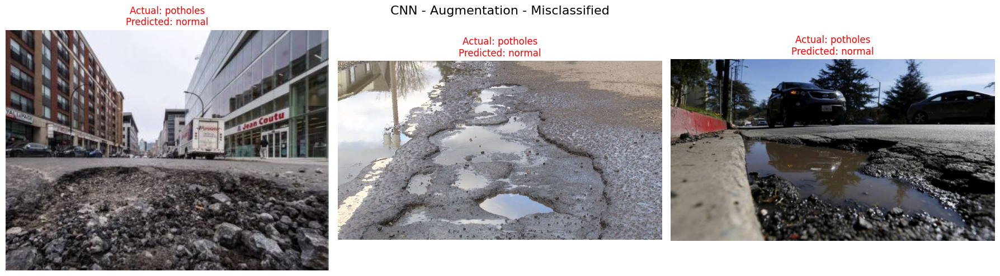

In [71]:
cnn_augmentation_visual_results = visualize_original_predictions(
    model=cnn_augmented,
    validation_loader=normal_val_loader,
    original_dataset=dataset,
    validation_indices=val_dataset.indices,
    class_names=class_names,
    model_name="CNN - Augmentation",
    max_correct=3,
    max_misclassified=3
)

In [53]:
# CELL 49: CNN + LSTM MODEL

class CNN_LSTM(nn.Module):

    def __init__(self, num_classes=2):

        super(CNN_LSTM, self).__init__()

        # CNN feature extractor
        self.cnn = CNN()

        # Remove original classification head
        self.cnn.fc_layers = nn.Identity()

        # CNN output: [B, 128, 8, 8]
        # Convert into sequence of 8 time steps
        self.feature_projection = nn.Linear(
            128 * 8, 256
        )

        self.lstm = nn.LSTM(
            input_size=256,
            hidden_size=128,
            num_layers=2,
            batch_first=True,
            dropout=0.3
        )

        self.classifier = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        features = self.cnn.conv_layers(x)

        batch_size = features.size(0)

        # [B, 128, 8, 8] -> [B, 8, 1024]
        features = features.permute(0, 2, 1, 3)

        features = features.reshape(
            batch_size, 8, 128 * 8
        )

        features = self.feature_projection(features)

        output, (hidden, cell) = self.lstm(features)

        final_features = hidden[-1]

        return self.classifier(final_features)


lstm_model = CNN_LSTM(
    num_classes=NUM_CLASSES
).to(device)

print(lstm_model)

CNN_LSTM(
  (cnn): CNN(
    (conv_layers): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): ReLU()
      (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (10): ReLU()
      (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (fc_layers): Identity()
  )
  (feature_projection): Linear(in_features=1024, out_features=256, bias=True)
  (lstm): 

CNN_LSTM | Epoch 1/10 | Train Loss: 0.6586 | Val Loss: 0.6450 | Train Acc: 62.32% | Val Acc: 59.85%
CNN_LSTM | Epoch 2/10 | Train Loss: 0.4904 | Val Loss: 0.6411 | Train Acc: 80.15% | Val Acc: 69.34%
CNN_LSTM | Epoch 3/10 | Train Loss: 0.3800 | Val Loss: 0.3290 | Train Acc: 85.48% | Val Acc: 85.40%
CNN_LSTM | Epoch 4/10 | Train Loss: 0.3698 | Val Loss: 0.3141 | Train Acc: 83.82% | Val Acc: 88.32%
CNN_LSTM | Epoch 5/10 | Train Loss: 0.3439 | Val Loss: 0.2815 | Train Acc: 87.87% | Val Acc: 88.32%
CNN_LSTM | Epoch 6/10 | Train Loss: 0.2832 | Val Loss: 0.2679 | Train Acc: 88.05% | Val Acc: 87.59%
CNN_LSTM | Epoch 7/10 | Train Loss: 0.3022 | Val Loss: 0.2072 | Train Acc: 87.87% | Val Acc: 91.97%
CNN_LSTM | Epoch 8/10 | Train Loss: 0.3043 | Val Loss: 0.4709 | Train Acc: 89.15% | Val Acc: 75.91%
CNN_LSTM | Epoch 9/10 | Train Loss: 0.3627 | Val Loss: 0.9098 | Train Acc: 86.03% | Val Acc: 62.04%
CNN_LSTM | Epoch 10/10 | Train Loss: 0.3199 | Val Loss: 0.2593 | Train Acc: 87.68% | Val Acc: 89.05%

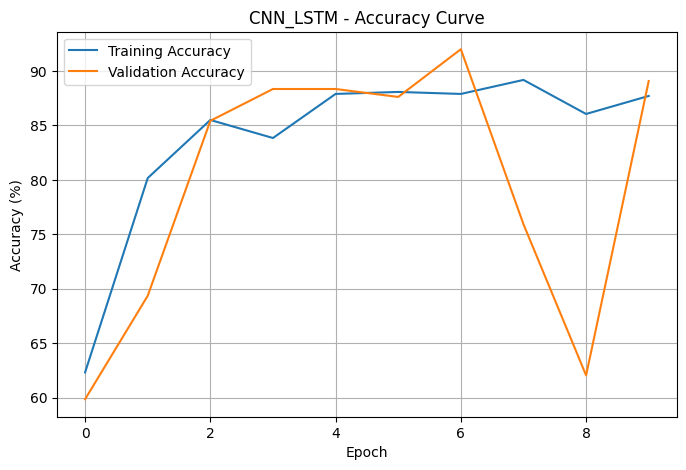

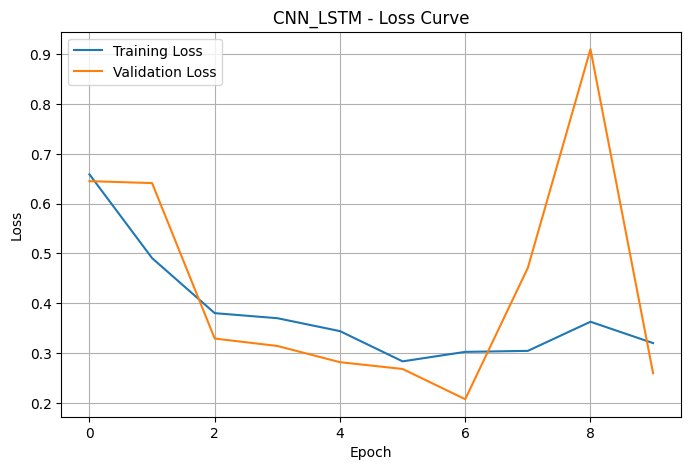

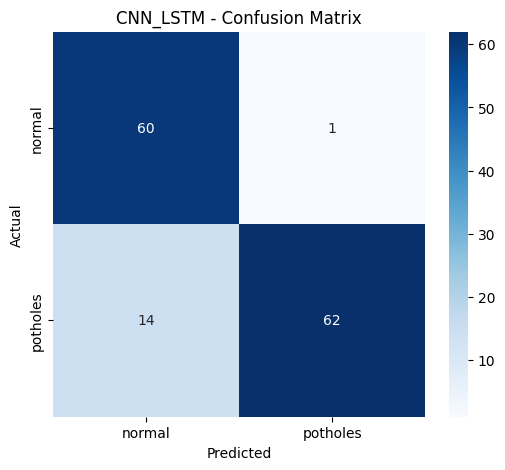

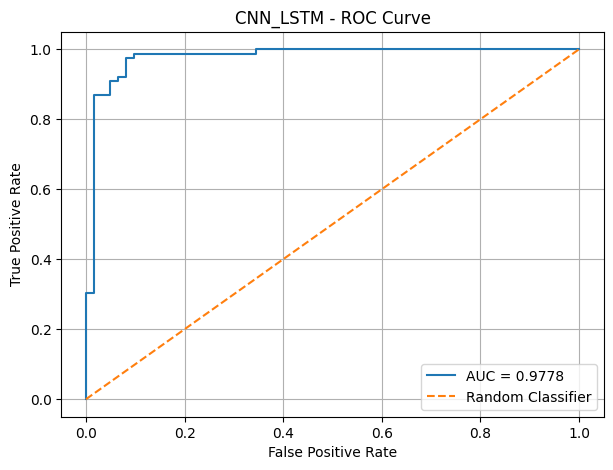


CNN_LSTM CLASSIFICATION REPORT

              precision    recall  f1-score   support

      normal       0.81      0.98      0.89        61
    potholes       0.98      0.82      0.89        76

    accuracy                           0.89       137
   macro avg       0.90      0.90      0.89       137
weighted avg       0.91      0.89      0.89       137

Checkpoint saved: pothole_checkpoints/CNN_LSTM.pth
CNN-LSTM experiment completed!


In [54]:
# CELL 50: TRAIN CNN-LSTM

lstm_optimizer = optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

lstm_results = run_experiment(
    model=lstm_model,
    train_loader=augmented_train_loader,
    val_loader=normal_val_loader,
    model_name="CNN_LSTM",
    optimizer=lstm_optimizer,
    epochs=NUM_EPOCHS
)

print("CNN-LSTM experiment completed!")

CNN-LSTM: 122 correctly classified, 15 misclassified out of 137 validation images.


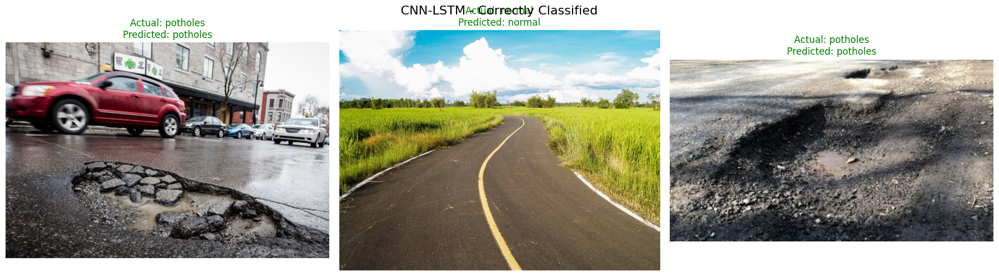

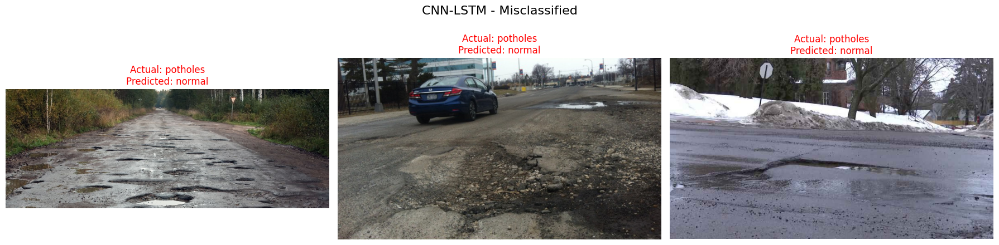

In [72]:
lstm_visual_results = visualize_original_predictions(
    model=lstm_model,
    validation_loader=normal_val_loader,
    original_dataset=dataset,
    validation_indices=val_dataset.indices,
    class_names=class_names,
    model_name="CNN-LSTM",
    max_correct=3,
    max_misclassified=3
)

In [55]:
# CELL 51: CNN + BIDIRECTIONAL GRU MODEL

class CNN_BiGRU(nn.Module):

    def __init__(self, num_classes=2):

        super(CNN_BiGRU, self).__init__()

        self.cnn = CNN()

        self.cnn.fc_layers = nn.Identity()

        self.feature_projection = nn.Linear(
            128 * 8, 256
        )

        self.bigru = nn.GRU(
            input_size=256,
            hidden_size=128,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.3
        )

        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        features = self.cnn.conv_layers(x)

        batch_size = features.size(0)

        features = features.permute(0, 2, 1, 3)

        features = features.reshape(
            batch_size, 8, 128 * 8
        )

        features = self.feature_projection(features)

        output, hidden = self.bigru(features)

        # Last forward and backward hidden states
        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        combined = torch.cat(
            [forward_hidden, backward_hidden],
            dim=1
        )

        return self.classifier(combined)


bigru_model = CNN_BiGRU(
    num_classes=NUM_CLASSES
).to(device)

print(bigru_model)

CNN_BiGRU(
  (cnn): CNN(
    (conv_layers): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): ReLU()
      (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (10): ReLU()
      (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (fc_layers): Identity()
  )
  (feature_projection): Linear(in_features=1024, out_features=256, bias=True)
  (bigru)

CNN_Bidirectional_GRU | Epoch 1/10 | Train Loss: 0.6314 | Val Loss: 0.6084 | Train Acc: 62.87% | Val Acc: 64.23%
CNN_Bidirectional_GRU | Epoch 2/10 | Train Loss: 0.4680 | Val Loss: 0.3565 | Train Acc: 80.33% | Val Acc: 81.75%
CNN_Bidirectional_GRU | Epoch 3/10 | Train Loss: 0.3979 | Val Loss: 0.6260 | Train Acc: 83.46% | Val Acc: 70.07%
CNN_Bidirectional_GRU | Epoch 4/10 | Train Loss: 0.3503 | Val Loss: 0.2857 | Train Acc: 86.21% | Val Acc: 89.78%
CNN_Bidirectional_GRU | Epoch 5/10 | Train Loss: 0.2804 | Val Loss: 0.2395 | Train Acc: 87.87% | Val Acc: 89.78%
CNN_Bidirectional_GRU | Epoch 6/10 | Train Loss: 0.2925 | Val Loss: 0.5444 | Train Acc: 88.05% | Val Acc: 71.53%
CNN_Bidirectional_GRU | Epoch 7/10 | Train Loss: 0.3124 | Val Loss: 1.5589 | Train Acc: 85.85% | Val Acc: 48.91%
CNN_Bidirectional_GRU | Epoch 8/10 | Train Loss: 0.2856 | Val Loss: 0.3103 | Train Acc: 87.32% | Val Acc: 83.94%
CNN_Bidirectional_GRU | Epoch 9/10 | Train Loss: 0.2585 | Val Loss: 0.4002 | Train Acc: 89.15% |

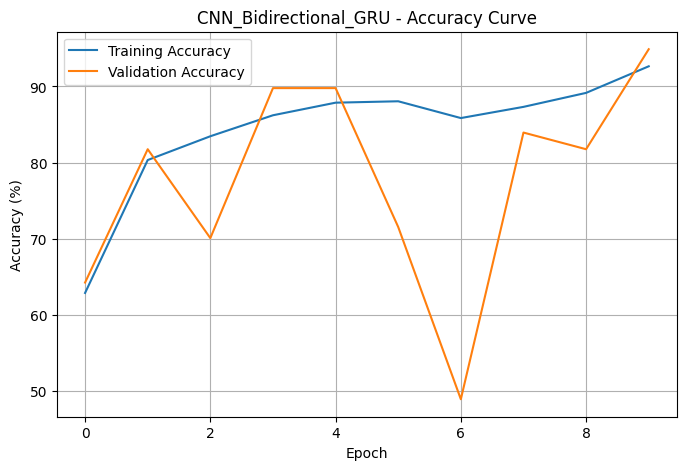

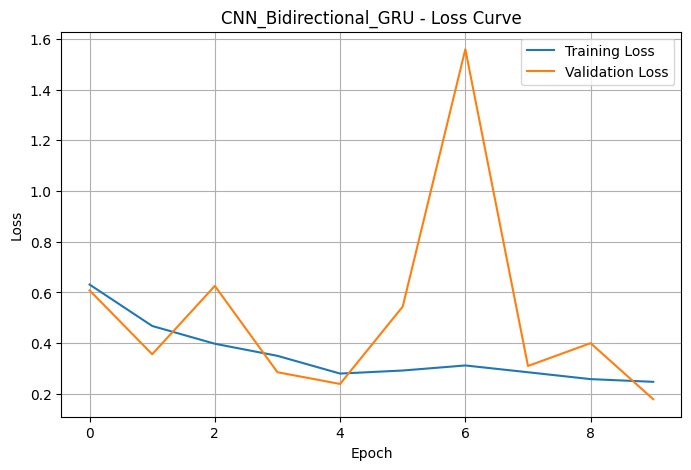

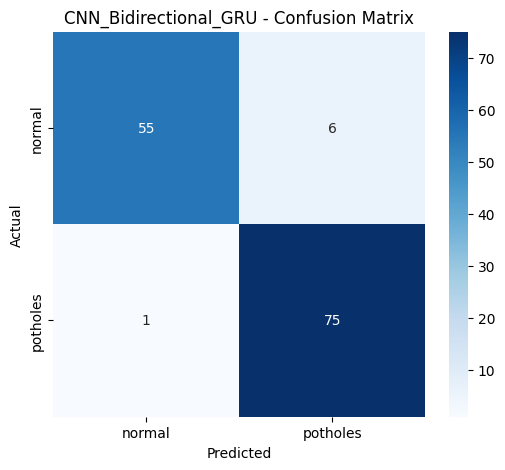

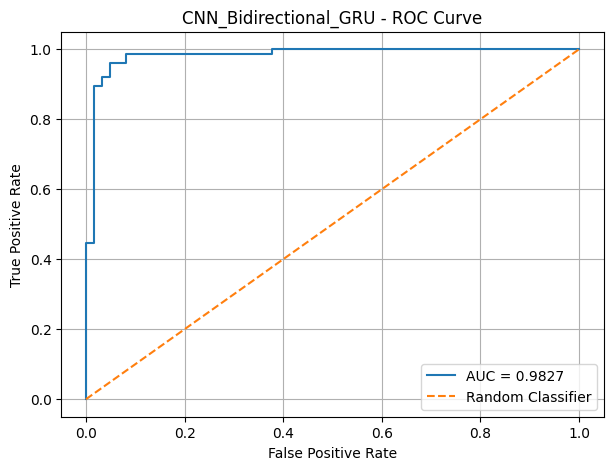


CNN_Bidirectional_GRU CLASSIFICATION REPORT

              precision    recall  f1-score   support

      normal       0.98      0.90      0.94        61
    potholes       0.93      0.99      0.96        76

    accuracy                           0.95       137
   macro avg       0.95      0.94      0.95       137
weighted avg       0.95      0.95      0.95       137

Checkpoint saved: pothole_checkpoints/CNN_Bidirectional_GRU.pth
Bidirectional GRU experiment completed!


In [56]:
# CELL 52: TRAIN CNN-BIGRU

bigru_optimizer = optim.Adam(
    bigru_model.parameters(),
    lr=0.001
)

bigru_results = run_experiment(
    model=bigru_model,
    train_loader=augmented_train_loader,
    val_loader=normal_val_loader,
    model_name="CNN_Bidirectional_GRU",
    optimizer=bigru_optimizer,
    epochs=NUM_EPOCHS
)

print("Bidirectional GRU experiment completed!")

CNN-BiGRU: 130 correctly classified, 7 misclassified out of 137 validation images.


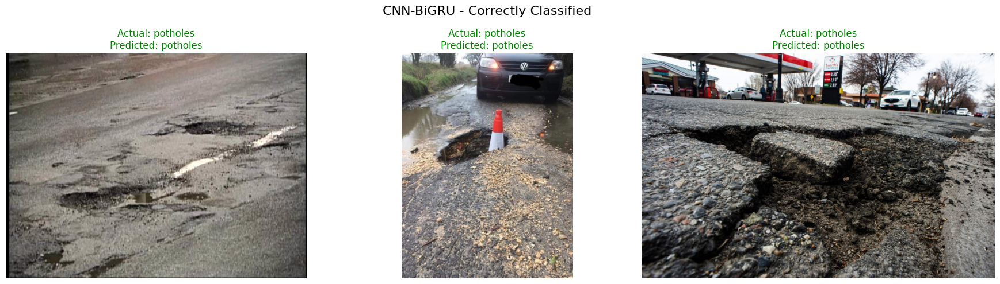

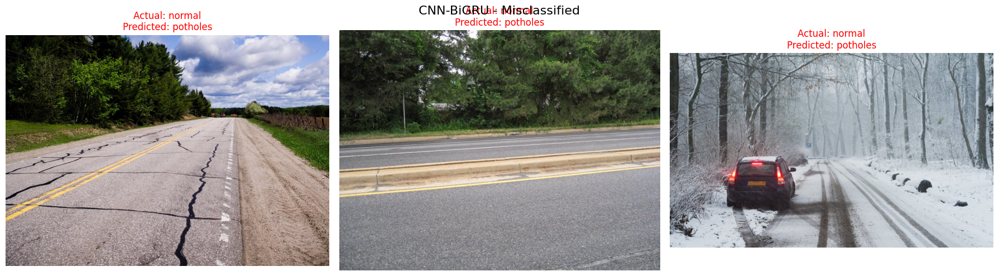

In [73]:
bigru_visual_results = visualize_original_predictions(
    model=bigru_model,
    validation_loader=normal_val_loader,
    original_dataset=dataset,
    validation_indices=val_dataset.indices,
    class_names=class_names,
    model_name="CNN-BiGRU",
    max_correct=3,
    max_misclassified=3
)

In [74]:
# CELL 53: GRAPH NEURAL NETWORK MODEL

class ImageGNN(nn.Module):

    def __init__(self, num_classes=2, hidden_dim=128):

        super(ImageGNN, self).__init__()

        self.hidden_dim = hidden_dim

        # Every 8x8 RGB patch has 192 features
        self.input_layer = nn.Linear(192, hidden_dim)

        self.gnn_layer1 = nn.Linear(
            hidden_dim, hidden_dim
        )

        self.gnn_layer2 = nn.Linear(
            hidden_dim, hidden_dim
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

        # Create adjacency matrix for 8x8 image grid
        adjacency = torch.eye(64)

        for i in range(8):
            for j in range(8):

                node = i * 8 + j

                if i > 0:
                    adjacency[node, node - 8] = 1

                if i < 7:
                    adjacency[node, node + 8] = 1

                if j > 0:
                    adjacency[node, node - 1] = 1

                if j < 7:
                    adjacency[node, node + 1] = 1

        # Symmetric degree normalization
        degree = adjacency.sum(dim=1)

        degree_inv_sqrt = torch.pow(
            degree, -0.5
        )

        degree_matrix = torch.diag(
            degree_inv_sqrt
        )

        adjacency = (
            degree_matrix @ adjacency @ degree_matrix
        )

        self.register_buffer(
            "adjacency", adjacency
        )

    def forward(self, images):

        # Convert image into 8x8 patches
        patches = F.unfold(
            images,
            kernel_size=8,
            stride=8
        )

        # [B, 192, 64] -> [B, 64, 192]
        patches = patches.transpose(1, 2)

        # Initial node representations
        x = F.relu(
            self.input_layer(patches)
        )

        # First graph convolution
        aggregated = torch.matmul(
            self.adjacency, x
        )

        x = F.relu(
            self.gnn_layer1(aggregated) + x
        )

        # Second graph convolution
        aggregated = torch.matmul(
            self.adjacency, x
        )

        x = F.relu(
            self.gnn_layer2(aggregated) + x
        )

        # Global mean pooling
        graph_features = x.mean(dim=1)

        return self.classifier(graph_features)


gnn_model = ImageGNN(
    num_classes=NUM_CLASSES
).to(device)

print(gnn_model)

ImageGNN(
  (input_layer): Linear(in_features=192, out_features=128, bias=True)
  (gnn_layer1): Linear(in_features=128, out_features=128, bias=True)
  (gnn_layer2): Linear(in_features=128, out_features=128, bias=True)
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=128, out_features=2, bias=True)
  )
)


Image_GNN | Epoch 1/10 | Train Loss: 0.6977 | Val Loss: 0.7009 | Train Acc: 49.63% | Val Acc: 44.53%
Image_GNN | Epoch 2/10 | Train Loss: 0.6941 | Val Loss: 0.7003 | Train Acc: 53.31% | Val Acc: 44.53%
Image_GNN | Epoch 3/10 | Train Loss: 0.6945 | Val Loss: 0.7025 | Train Acc: 53.31% | Val Acc: 44.53%
Image_GNN | Epoch 4/10 | Train Loss: 0.6911 | Val Loss: 0.6961 | Train Acc: 53.49% | Val Acc: 44.53%
Image_GNN | Epoch 5/10 | Train Loss: 0.6879 | Val Loss: 0.6948 | Train Acc: 54.23% | Val Acc: 44.53%
Image_GNN | Epoch 6/10 | Train Loss: 0.6789 | Val Loss: 0.6632 | Train Acc: 54.04% | Val Acc: 44.53%
Image_GNN | Epoch 7/10 | Train Loss: 0.6356 | Val Loss: 0.5611 | Train Acc: 61.03% | Val Acc: 82.48%
Image_GNN | Epoch 8/10 | Train Loss: 0.5184 | Val Loss: 0.4386 | Train Acc: 73.53% | Val Acc: 77.37%
Image_GNN | Epoch 9/10 | Train Loss: 0.4291 | Val Loss: 0.3880 | Train Acc: 80.33% | Val Acc: 84.67%
Image_GNN | Epoch 10/10 | Train Loss: 0.4137 | Val Loss: 0.3679 | Train Acc: 79.78% | Val A

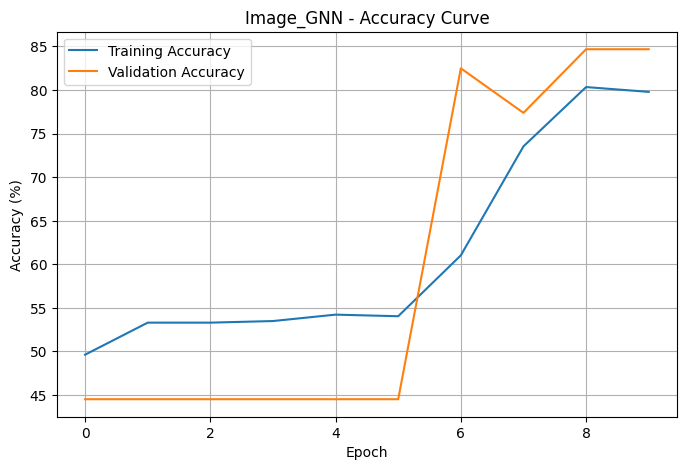

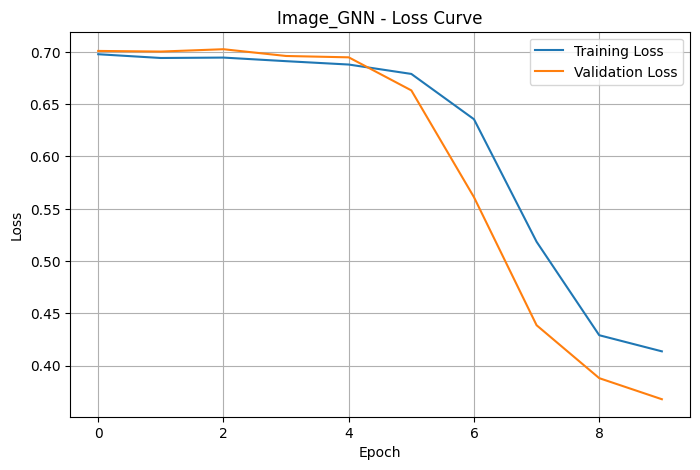

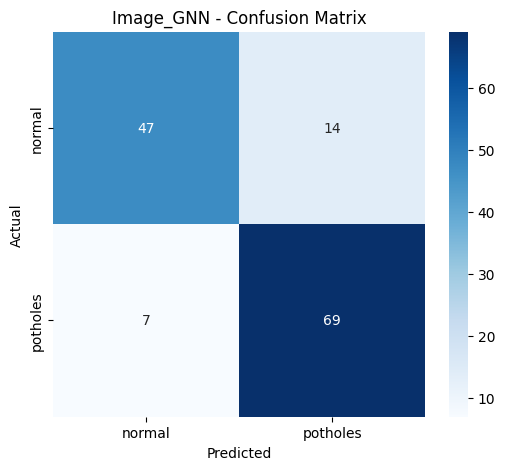

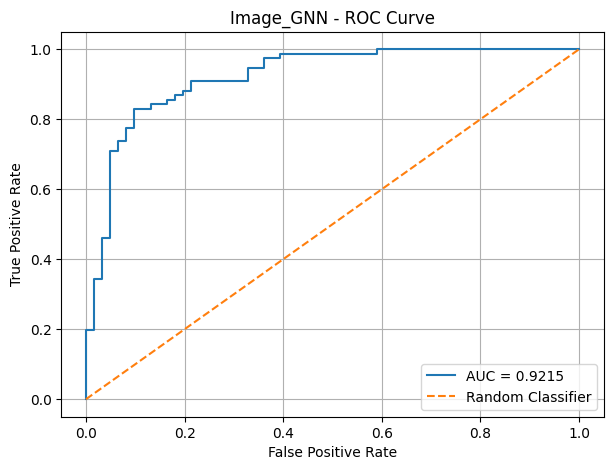


Image_GNN CLASSIFICATION REPORT

              precision    recall  f1-score   support

      normal       0.87      0.77      0.82        61
    potholes       0.83      0.91      0.87        76

    accuracy                           0.85       137
   macro avg       0.85      0.84      0.84       137
weighted avg       0.85      0.85      0.85       137

Checkpoint saved: pothole_checkpoints/Image_GNN.pth
GNN experiment completed!


In [75]:
# CELL 54: TRAIN GRAPH NEURAL NETWORK

gnn_optimizer = optim.Adam(
    gnn_model.parameters(),
    lr=0.001
)

gnn_results = run_experiment(
    model=gnn_model,
    train_loader=augmented_train_loader,
    val_loader=normal_val_loader,
    model_name="Image_GNN",
    optimizer=gnn_optimizer,
    epochs=NUM_EPOCHS
)

print("GNN experiment completed!")

Image GNN: 116 correctly classified, 21 misclassified out of 137 validation images.


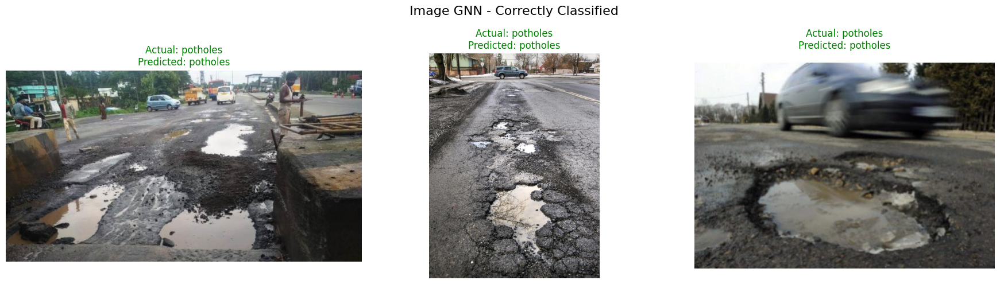

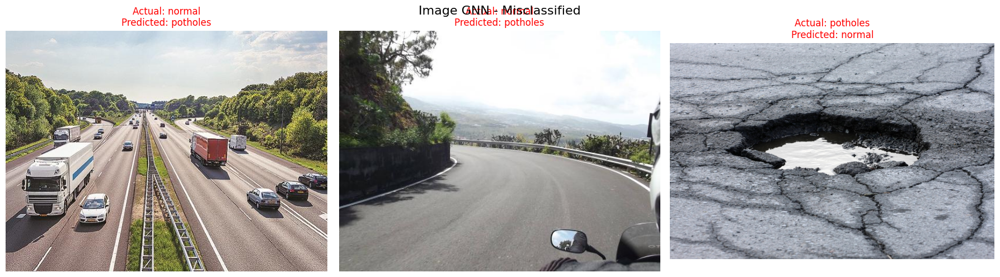

In [76]:
gnn_visual_results = visualize_original_predictions(
    model=gnn_model,
    validation_loader=normal_val_loader,
    original_dataset=dataset,
    validation_indices=val_dataset.indices,
    class_names=class_names,
    model_name="Image GNN",
    max_correct=3,
    max_misclassified=3
)

In [80]:
# CELL 55: GAN TRAINING DATASET

gan_transform = transforms.Compose([

    transforms.Resize((64, 64)),

    transforms.ToTensor(),

    # Normalize images to [-1, 1]
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )

])

gan_dataset = datasets.ImageFolder(
    root=DATASET_PATH,
    transform=gan_transform
)

gan_train_dataset = Subset(
    gan_dataset,
    train_dataset.indices
)

gan_train_loader = DataLoader(
    gan_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("GAN training images:", len(gan_train_dataset))
print("GAN classes:", gan_dataset.classes)

GAN training images: 544
GAN classes: ['normal', 'potholes']


In [85]:
from torch.utils.data import Subset, DataLoader
from torchvision import transforms, datasets

gan_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

gan_dataset = datasets.ImageFolder(
    DATASET_PATH,
    transform=gan_transform
)

gan_train_dataset = Subset(
    gan_dataset,
    train_dataset.indices
)

gan_train_loader = DataLoader(
    gan_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("GAN training images:", len(gan_train_dataset))

GAN training images: 544


In [86]:
# CELL 56: CONDITIONAL DCGAN ARCHITECTURE

LATENT_DIM = 100
LABEL_EMBEDDING_DIM = 50


class Generator(nn.Module):

    def __init__(self, num_classes):

        super(Generator, self).__init__()

        self.label_embedding = nn.Embedding(
            num_classes,
            LABEL_EMBEDDING_DIM
        )

        self.fc = nn.Linear(
            LATENT_DIM + LABEL_EMBEDDING_DIM,
            512 * 4 * 4
        )

        self.generator = nn.Sequential(

            nn.BatchNorm2d(512),

            nn.ConvTranspose2d(
                512, 256, 4, 2, 1
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                256, 128, 4, 2, 1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                128, 64, 4, 2, 1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                64, 3, 4, 2, 1
            ),

            nn.Tanh()
        )

    def forward(self, noise, labels):

        label_features = self.label_embedding(labels)

        combined = torch.cat(
            [noise, label_features],
            dim=1
        )

        x = self.fc(combined)

        x = x.view(-1, 512, 4, 4)

        return self.generator(x)


class Discriminator(nn.Module):

    def __init__(self, num_classes):

        super(Discriminator, self).__init__()

        self.label_embedding = nn.Embedding(
            num_classes, 64 * 64
        )

        self.discriminator = nn.Sequential(

            nn.Conv2d(
                4, 64, 4, 2, 1
            ),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                64, 128, 4, 2, 1
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                128, 256, 4, 2, 1
            ),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                256, 512, 4, 2, 1
            ),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                512, 1, 4, 1, 0
            ),
        )

    def forward(self, images, labels):

        label_map = self.label_embedding(labels)

        label_map = label_map.view(
            -1, 1, 64, 64
        )

        combined = torch.cat(
            [images, label_map],
            dim=1
        )

        return self.discriminator(combined).view(-1)


generator = Generator(
    NUM_CLASSES
).to(device)

discriminator = Discriminator(
    NUM_CLASSES
).to(device)

print("Generator parameters:",
      sum(p.numel() for p in generator.parameters()))

print("Discriminator parameters:",
      sum(p.numel() for p in discriminator.parameters()))

Generator parameters: 3995047
Discriminator parameters: 2775745


In [88]:
# CELL 57: TRAIN CONDITIONAL DCGAN

GAN_EPOCHS = 100

gan_criterion = nn.BCEWithLogitsLoss()

generator_optimizer = optim.Adam(
    generator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

discriminator_optimizer = optim.Adam(
    discriminator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

generator_losses = []
discriminator_losses = []

start_time = time.time()

for epoch in range(GAN_EPOCHS):

    generator.train()
    discriminator.train()

    g_running_loss = 0.0
    d_running_loss = 0.0

    for real_images, labels in gan_train_loader:

        real_images = real_images.to(device)
        labels = labels.to(device)

        batch_size = real_images.size(0)

        real_targets = torch.ones(
            batch_size, device=device
        ) * 0.9

        fake_targets = torch.zeros(
            batch_size, device=device
        )

        # ---------------- TRAIN DISCRIMINATOR ----------------

        discriminator_optimizer.zero_grad()

        real_output = discriminator(
            real_images, labels
        )

        real_loss = gan_criterion(
            real_output, real_targets
        )

        noise = torch.randn(
            batch_size, LATENT_DIM, device=device
        )

        fake_images = generator(noise, labels)

        fake_output = discriminator(
            fake_images.detach(), labels
        )

        fake_loss = gan_criterion(
            fake_output, fake_targets
        )

        d_loss = real_loss + fake_loss

        d_loss.backward()

        discriminator_optimizer.step()

        # ---------------- TRAIN GENERATOR ----------------

        generator_optimizer.zero_grad()
        
        # Freeze discriminator parameters during generator update
        for param in discriminator.parameters():
            param.requires_grad = False
        
        noise = torch.randn(
            batch_size, LATENT_DIM, device=device
        )
        
        generated_images = generator(
            noise, labels
        )
        
        fake_output = discriminator(
            generated_images, labels
        )
        
        g_loss = gan_criterion(
            fake_output,
            torch.ones(batch_size, device=device)
        )
        
        g_loss.backward()
        
        generator_optimizer.step()

        # Record batch losses
        d_running_loss += d_loss.item()
        g_running_loss += g_loss.item()
        
        # Enable discriminator gradients again
        for param in discriminator.parameters():
            param.requires_grad = True

        

    d_epoch_loss = (
    d_running_loss / len(gan_train_loader)
    )
    
    g_epoch_loss = (
        g_running_loss / len(gan_train_loader)
    )
    
    discriminator_losses.append(d_epoch_loss)
    generator_losses.append(g_epoch_loss)
    
    print(
        f"GAN Epoch [{epoch+1}/{GAN_EPOCHS}] "
        f"D Loss: {d_epoch_loss:.6f} "
        f"G Loss: {g_epoch_loss:.6f}"
    )

gan_training_time = time.time() - start_time

print("GAN training completed!")
print("Training time:", round(gan_training_time, 2), "seconds")

GAN Epoch [1/100] D Loss: 0.544423 G Loss: 5.362712
GAN Epoch [2/100] D Loss: 0.875915 G Loss: 5.279116
GAN Epoch [3/100] D Loss: 0.759530 G Loss: 5.464815
GAN Epoch [4/100] D Loss: 0.700222 G Loss: 4.682123
GAN Epoch [5/100] D Loss: 0.762872 G Loss: 4.734632
GAN Epoch [6/100] D Loss: 0.618097 G Loss: 4.621682
GAN Epoch [7/100] D Loss: 0.525059 G Loss: 4.326737
GAN Epoch [8/100] D Loss: 0.636616 G Loss: 4.573191
GAN Epoch [9/100] D Loss: 0.775755 G Loss: 5.208428
GAN Epoch [10/100] D Loss: 0.811856 G Loss: 4.724956
GAN Epoch [11/100] D Loss: 0.649195 G Loss: 4.616455
GAN Epoch [12/100] D Loss: 0.783529 G Loss: 5.582937
GAN Epoch [13/100] D Loss: 0.777579 G Loss: 4.529235
GAN Epoch [14/100] D Loss: 0.837527 G Loss: 4.901545
GAN Epoch [15/100] D Loss: 0.778934 G Loss: 5.241432
GAN Epoch [16/100] D Loss: 0.628113 G Loss: 4.025461
GAN Epoch [17/100] D Loss: 0.636360 G Loss: 4.392472
GAN Epoch [18/100] D Loss: 0.687552 G Loss: 5.010526
GAN Epoch [19/100] D Loss: 0.606279 G Loss: 3.923133
GA

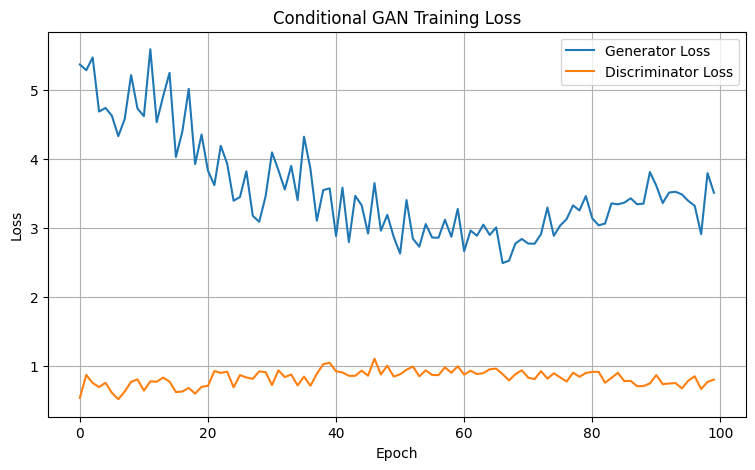

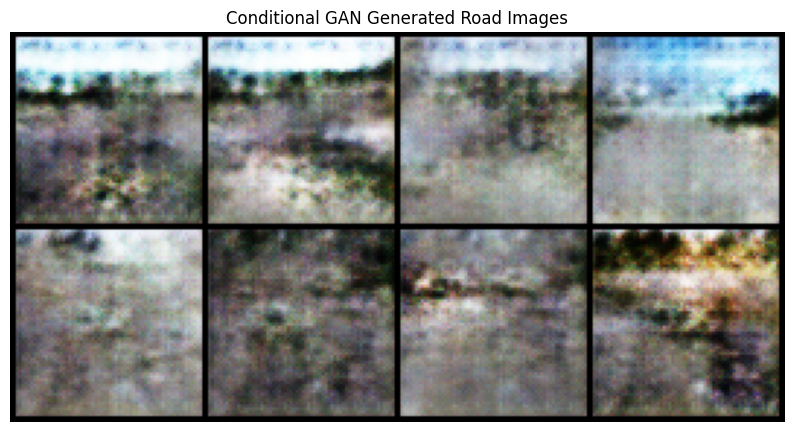

In [89]:
# CELL 58: GAN TRAINING LOSS CURVES

plt.figure(figsize=(9, 5))

plt.plot(
    generator_losses,
    label="Generator Loss"
)

plt.plot(
    discriminator_losses,
    label="Discriminator Loss"
)

plt.title("Conditional GAN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    f"{CHECKPOINT_DIR}/GAN_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# SAVE GENERATOR AND DISCRIMINATOR

torch.save(
    generator.state_dict(),
    f"{CHECKPOINT_DIR}/Conditional_GAN_Generator.pth"
)

torch.save(
    discriminator.state_dict(),
    f"{CHECKPOINT_DIR}/Conditional_GAN_Discriminator.pth"
)


# GENERATE SAMPLE IMAGES FOR EACH CLASS

generator.eval()

fixed_noise = torch.randn(
    8, LATENT_DIM, device=device
)

fixed_labels = torch.tensor(
    [0, 0, 0, 0, 1, 1, 1, 1],
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    samples = generator(
        fixed_noise,
        fixed_labels
    )

    samples = (samples + 1) / 2
    samples = samples.clamp(0, 1)

grid = make_grid(
    samples.cpu(),
    nrow=4
)

plt.figure(figsize=(10, 6))
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.title("Conditional GAN Generated Road Images")
plt.axis("off")
plt.show()

In [90]:
# CELL 59: GENERATE SYNTHETIC DATASET

GAN_SYNTH_PER_CLASS = 100

synthetic_images = []
synthetic_labels = []

generator.eval()

with torch.no_grad():

    for class_index in range(NUM_CLASSES):

        remaining = GAN_SYNTH_PER_CLASS

        while remaining > 0:

            current_batch = min(32, remaining)

            noise = torch.randn(
                current_batch,
                LATENT_DIM,
                device=device
            )

            labels = torch.full(
                (current_batch,),
                class_index,
                dtype=torch.long,
                device=device
            )

            generated = generator(
                noise, labels
            )

            # Convert to [0, 1] for CNN training
            generated = (generated + 1) / 2

            synthetic_images.append(
                generated.cpu()
            )

            synthetic_labels.append(
                labels.cpu()
            )

            remaining -= current_batch


synthetic_images = torch.cat(
    synthetic_images, dim=0
)

synthetic_labels = torch.cat(
    synthetic_labels, dim=0
)

print("Synthetic image shape:", synthetic_images.shape)
print("Synthetic labels shape:", synthetic_labels.shape)

for i, class_name in enumerate(CLASS_NAMES):

    count = (
        synthetic_labels == i
    ).sum().item()

    print(f"{class_name}: {count} synthetic images")

Synthetic image shape: torch.Size([200, 3, 64, 64])
Synthetic labels shape: torch.Size([200])
normal: 100 synthetic images
potholes: 100 synthetic images


In [93]:
# CELL 60: COMBINE REAL AND GAN-GENERATED IMAGES

synthetic_dataset = TensorDataset(
    synthetic_images,
    synthetic_labels
)

gan_augmented_train_dataset = ConcatDataset([
    train_dataset,
    synthetic_dataset
])

gan_augmented_train_loader = DataLoader(
    gan_augmented_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

print(
    "Original training images:",
    len(train_dataset)
)

print(
    "Synthetic training images:",
    len(synthetic_dataset)
)

print(
    "Total GAN-augmented training images:",
    len(gan_augmented_train_dataset)
)

Original training images: 544
Synthetic training images: 200
Total GAN-augmented training images: 744


In [95]:
# Inspect the first sample
sample = gan_augmented_train_loader.dataset[0]

print("Number of returned elements:", len(sample))
print("Image type:", type(sample[0]))
print("Label type:", type(sample[1]))
print("Image shape:", sample[0].shape)
print("Label:", sample[1])

Number of returned elements: 2
Image type: <class 'torch.Tensor'>
Label type: <class 'int'>
Image shape: torch.Size([3, 64, 64])
Label: 1


In [96]:
ds = gan_augmented_train_loader.dataset

print("Dataset type:", type(ds))
print("Total samples:", len(ds))

for i in [0, 1, 2, len(ds)//2, len(ds)-3, len(ds)-2, len(ds)-1]:
    sample = ds[i]

    print(f"\nSample {i}")
    print("Number of elements:", len(sample))
    print("Image type:", type(sample[0]))
    print("Image shape:", getattr(sample[0], "shape", None))
    print("Label type:", type(sample[1]))
    print("Label:", sample[1])

Dataset type: <class 'torch.utils.data.dataset.ConcatDataset'>
Total samples: 744

Sample 0
Number of elements: 2
Image type: <class 'torch.Tensor'>
Image shape: torch.Size([3, 64, 64])
Label type: <class 'int'>
Label: 1

Sample 1
Number of elements: 2
Image type: <class 'torch.Tensor'>
Image shape: torch.Size([3, 64, 64])
Label type: <class 'int'>
Label: 1

Sample 2
Number of elements: 2
Image type: <class 'torch.Tensor'>
Image shape: torch.Size([3, 64, 64])
Label type: <class 'int'>
Label: 0

Sample 372
Number of elements: 2
Image type: <class 'torch.Tensor'>
Image shape: torch.Size([3, 64, 64])
Label type: <class 'int'>
Label: 0

Sample 741
Number of elements: 2
Image type: <class 'torch.Tensor'>
Image shape: torch.Size([3, 64, 64])
Label type: <class 'torch.Tensor'>
Label: tensor(1)

Sample 742
Number of elements: 2
Image type: <class 'torch.Tensor'>
Image shape: torch.Size([3, 64, 64])
Label type: <class 'torch.Tensor'>
Label: tensor(1)

Sample 743
Number of elements: 2
Image type

In [97]:
try:
    images, labels = next(iter(gan_augmented_train_loader))

    print("Batch created successfully!")
    print("Images:", images.shape, images.dtype)
    print("Labels:", labels.shape, labels.dtype)
    print("Unique labels:", torch.unique(labels))

except Exception as e:
    print("Batch error:", repr(e))

Batch created successfully!
Images: torch.Size([32, 3, 64, 64]) torch.float32
Labels: torch.Size([32]) torch.int64
Unique labels: tensor([0, 1])


In [98]:
from torch.utils.data import Dataset, DataLoader

class ConsistentLabelDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, label = self.dataset[index]

        label = int(label.item()) if torch.is_tensor(label) else int(label)

        return image, label


fixed_gan_dataset = ConsistentLabelDataset(
    gan_augmented_train_loader.dataset
)

gan_augmented_train_loader = DataLoader(
    fixed_gan_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

print("Fixed dataset:", len(gan_augmented_train_loader.dataset))

images, labels = next(iter(gan_augmented_train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Label dtype:", labels.dtype)
print("Unique labels:", torch.unique(labels))

Fixed dataset: 744
Images: torch.Size([32, 3, 64, 64])
Labels: torch.Size([32])
Label dtype: torch.int64
Unique labels: tensor([0, 1])


CNN_GAN_Augmented | Epoch 1/10 | Train Loss: 1.4434 | Val Loss: 1.8283 | Train Acc: 69.35% | Val Acc: 61.31%
CNN_GAN_Augmented | Epoch 2/10 | Train Loss: 0.4972 | Val Loss: 0.2979 | Train Acc: 84.81% | Val Acc: 86.13%
CNN_GAN_Augmented | Epoch 3/10 | Train Loss: 0.2906 | Val Loss: 0.2171 | Train Acc: 88.58% | Val Acc: 91.24%
CNN_GAN_Augmented | Epoch 4/10 | Train Loss: 0.1880 | Val Loss: 0.1645 | Train Acc: 92.34% | Val Acc: 91.24%
CNN_GAN_Augmented | Epoch 5/10 | Train Loss: 0.1620 | Val Loss: 0.1764 | Train Acc: 93.55% | Val Acc: 92.70%
CNN_GAN_Augmented | Epoch 6/10 | Train Loss: 0.1919 | Val Loss: 0.1988 | Train Acc: 91.94% | Val Acc: 91.97%
CNN_GAN_Augmented | Epoch 7/10 | Train Loss: 0.1372 | Val Loss: 0.3007 | Train Acc: 94.49% | Val Acc: 87.59%
CNN_GAN_Augmented | Epoch 8/10 | Train Loss: 0.1598 | Val Loss: 0.2105 | Train Acc: 93.55% | Val Acc: 94.16%
CNN_GAN_Augmented | Epoch 9/10 | Train Loss: 0.2034 | Val Loss: 1.0346 | Train Acc: 92.61% | Val Acc: 52.55%
CNN_GAN_Augmented |

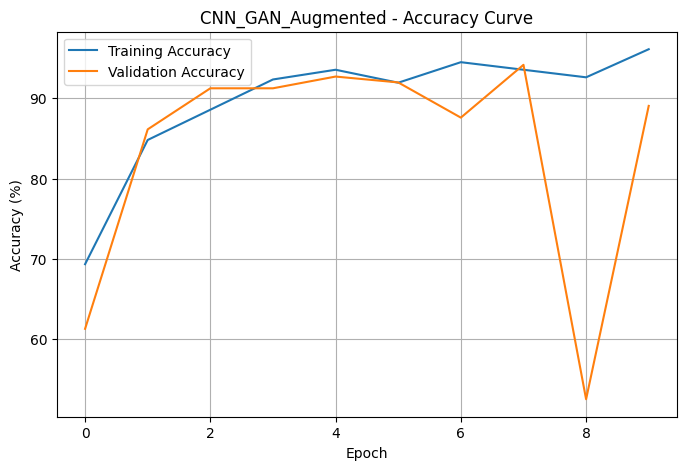

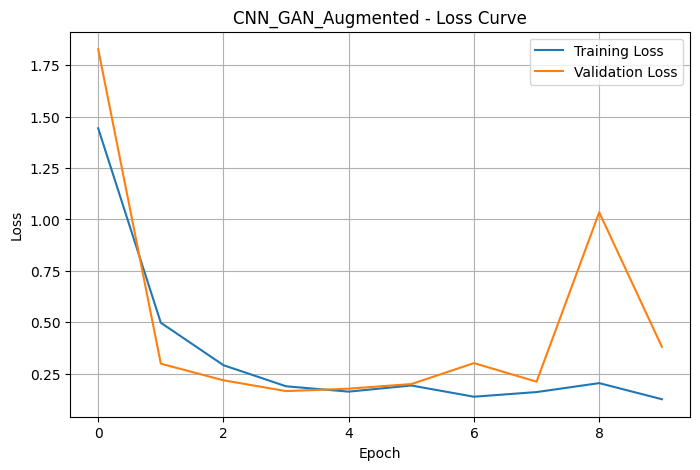

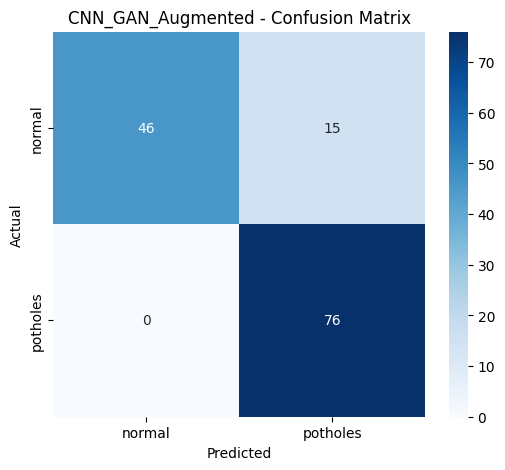

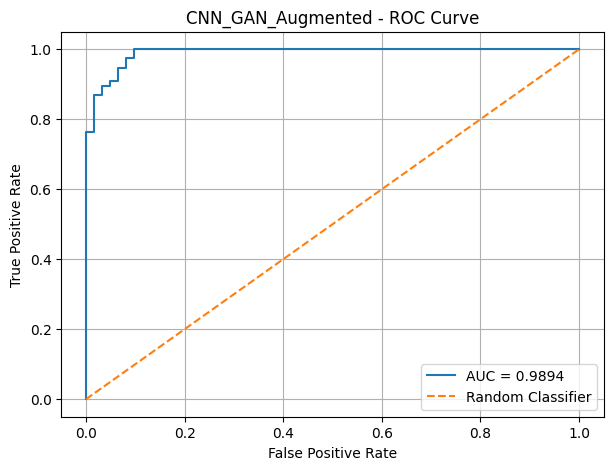


CNN_GAN_Augmented CLASSIFICATION REPORT

              precision    recall  f1-score   support

      normal       1.00      0.75      0.86        61
    potholes       0.84      1.00      0.91        76

    accuracy                           0.89       137
   macro avg       0.92      0.88      0.88       137
weighted avg       0.91      0.89      0.89       137

Checkpoint saved: pothole_checkpoints/CNN_GAN_Augmented.pth
GAN-augmented CNN experiment completed!


In [99]:
# CELL 61: CNN WITH GAN DATA AUGMENTATION

gan_augmented_cnn = CNN().to(device)

gan_cnn_optimizer = optim.Adam(
    gan_augmented_cnn.parameters(),
    lr=0.001
)

gan_augmented_results = run_experiment(
    model=gan_augmented_cnn,
    train_loader=gan_augmented_train_loader,
    val_loader=normal_val_loader,
    model_name="CNN_GAN_Augmented",
    optimizer=gan_cnn_optimizer,
    epochs=NUM_EPOCHS
)

print("GAN-augmented CNN experiment completed!")

In [100]:
# CELL 62: FINAL COMPARISON OF ALL MODELS

all_experiment_results = [

    # Original models
    {
        "Model": "Custom CNN",
        "Accuracy": cnn_accuracy,
        "Precision": cnn_precision,
        "Recall": cnn_recall,
        "F1 Score": cnn_f1,
        "AUC": roc_auc
    },

    {
        "Model": "ResNet18",
        "Accuracy": resnet_accuracy,
        "Precision": resnet_precision,
        "Recall": resnet_recall,
        "F1 Score": resnet_f1,
        "AUC": roc_auc_resnet
    }
]

# Add optimizer experiments
all_experiment_results.extend([
    {
        key: result[key]
        for key in [
            "Model", "Accuracy", "Precision",
            "Recall", "F1 Score", "AUC"
        ]
    }
    for result in optimizer_results
])

# Add other experiments
additional_results = [
    augmentation_results,
    lstm_results,
    bigru_results,
    gnn_results,
    gan_augmented_results
]

all_experiment_results.extend([
    {
        key: result[key]
        for key in [
            "Model", "Accuracy", "Precision",
            "Recall", "F1 Score", "AUC"
        ]
    }
    for result in additional_results
])

final_comparison_df = pd.DataFrame(
    all_experiment_results
)

print("FINAL DEEP LEARNING MODEL COMPARISON")

display(
    final_comparison_df.round(4)
)

# Save comparison
final_comparison_df.to_csv(
    "final_model_comparison.csv",
    index=False
)

print("Final comparison saved!")

FINAL DEEP LEARNING MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,AUC
0,Custom CNN,0.9270,0.8929,0.9868,0.9375,0.9894
1,ResNet18,1.0000,1.0000,1.0000,1.0000,1.0000
2,CNN_Adam,0.9270,0.9342,0.9342,0.9342,0.9802
3,CNN_SGD,0.8832,0.8409,0.9737,0.9024,0.9881
4,CNN_RMSprop,0.8978,0.8780,0.9474,0.9114,0.9711
5,CNN_Advanced_Augmentation,0.8321,0.9649,0.7237,0.8271,0.9698
6,CNN_LSTM,0.8905,0.9841,0.8158,0.8921,0.9778
7,CNN_Bidirectional_GRU,0.9489,0.9259,0.9868,0.9554,0.9827
8,Image_GNN,0.8467,0.8313,0.9079,0.8679,0.9215
9,CNN_GAN_Augmented,0.8905,0.8352,1.0000,0.9102,0.9894


Final comparison saved!


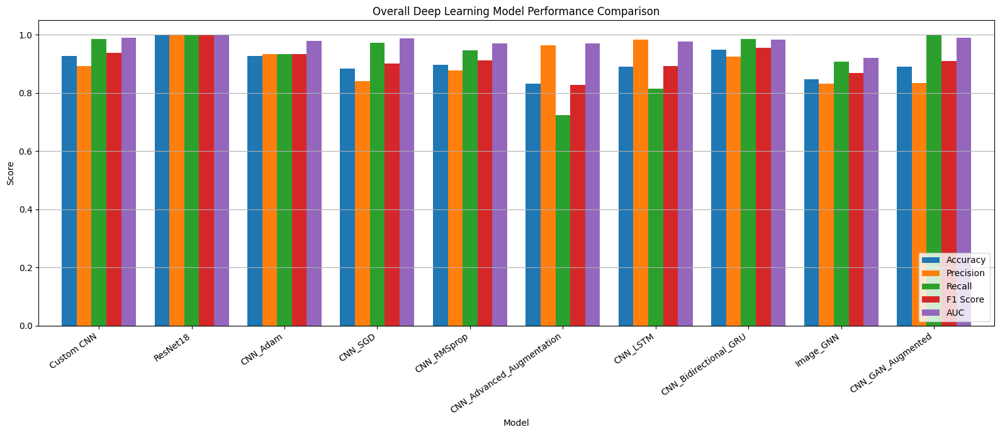

In [101]:
# CELL 63: OVERALL MODEL PERFORMANCE GRAPH

comparison_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "AUC"
]

final_comparison_df.set_index(
    "Model"
)[comparison_metrics].plot(
    kind="bar",
    figsize=(16, 7),
    width=0.8
)

plt.title(
    "Overall Deep Learning Model Performance Comparison"
)

plt.ylabel("Score")
plt.xlabel("Model")

plt.ylim(0, 1.05)

plt.xticks(rotation=35, ha="right")

plt.legend(loc="lower right")

plt.grid(axis="y")

plt.tight_layout()

plt.savefig(
    "overall_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

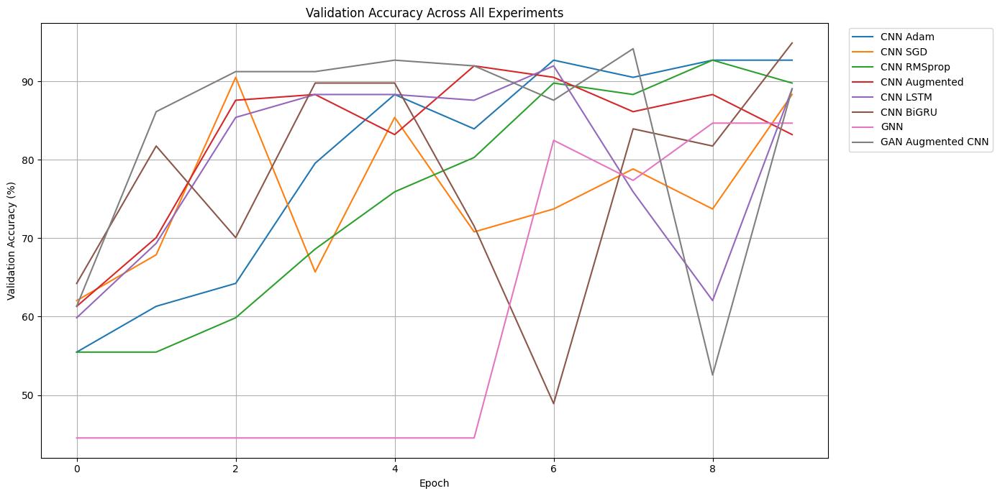

In [102]:
# CELL 64: TRAINING ACCURACY COMPARISON

histories = {
    "CNN Adam": adam_results["History"],
    "CNN SGD": sgd_results["History"],
    "CNN RMSprop": rmsprop_results["History"],
    "CNN Augmented": augmentation_results["History"],
    "CNN LSTM": lstm_results["History"],
    "CNN BiGRU": bigru_results["History"],
    "GNN": gnn_results["History"],
    "GAN Augmented CNN": gan_augmented_results["History"]
}

plt.figure(figsize=(14, 7))

for name, history in histories.items():

    plt.plot(
        history["val_accuracy"],
        label=name
    )

plt.title("Validation Accuracy Across All Experiments")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "all_models_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

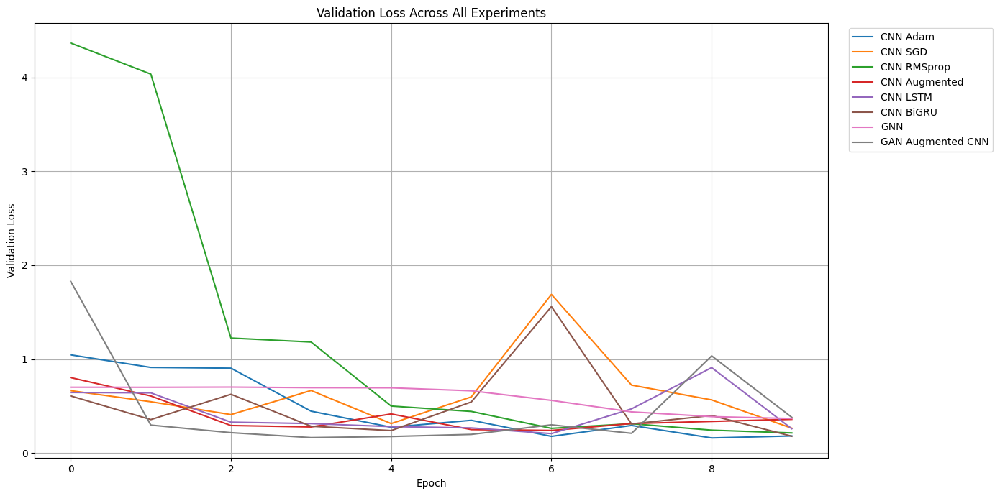

In [103]:
# CELL 65: VALIDATION LOSS COMPARISON

plt.figure(figsize=(14, 7))

for name, history in histories.items():

    plt.plot(
        history["val_loss"],
        label=name
    )

plt.title("Validation Loss Across All Experiments")

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "all_models_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [105]:
# CELL 66: BEST MODEL IDENTIFICATION

best_model = final_comparison_df.loc[
    final_comparison_df["Accuracy"].idxmax()
]

print("BEST PERFORMING CLASSIFICATION MODEL")

print("Model:", best_model["Model"])

print(
    "Accuracy:",
    round(best_model["Accuracy"] * 100, 2), "%"
)

print(
    "Precision:",
    round(best_model["Precision"] * 100, 2), "%"
)

print(
    "Recall:",
    round(best_model["Recall"] * 100, 2), "%"
)

print(
    "F1 Score:",
    round(best_model["F1 Score"], 4)
)

print(
    "ROC AUC:",
    round(best_model["AUC"], 4)
)

BEST PERFORMING CLASSIFICATION MODEL
Model: ResNet18
Accuracy: 100.0 %
Precision: 100.0 %
Recall: 100.0 %
F1 Score: 1.0
ROC AUC: 1.0
